# AfriMarket — Analyse stratégique de 6 mois d'activité e-commerce
**Rôle :** Data Analyst · **Période :** 1er juillet – 31 décembre 2025 · **Périmètre :** 8 villes, 4 catégories, 4 canaux marketing

---
### Sommaire
1. [Cadre, définitions et hypothèses](#1.-Cadre,-définitions-et-hypothèses)
2. [Audit des données](#2.-Audit-des-données)
3. [Nettoyage → `df_clean`](#3.-Data-cleaning)
4. [Feature engineering](#4.-Feature-engineering)
5. [Analyses](#5.-Analyses) : 5.1 Performance globale · 5.2 Catégories · 5.3 Villes · 5.4 Marketing · 5.5 Clients
6. [Test de robustesse](#6.-Test-de-robustesse)
7. [Les 5 recommandations stratégiques](#7.-Recommandations-stratégiques)
8. [Conclusion orientée action](#8.-Conclusion)

> **Lecture rapide (le « so what »).** Le chiffre d'affaires est porté à 71 % par l'Électronique, mais c'est aussi là que 15,6 % des commandes sont retournées.
> Douala perd 12,9 % de ses commandes en annulations (≈ 0 % partout ailleurs). Instagram absorbe 54 % du budget marketing pour le plus faible rendement.
> Chaque point est chiffré plus bas ; le plan d'action représente environ **+60 k UM de profit (+13 %)** sur 6 mois.

## 1. Cadre, définitions et hypothèses

Le jeu de données ne contient ni coût d'achat des produits ni devise. Les choix ci-dessous sont **explicites et modifiables** (ils sont centralisés dans `src/afrimarket_pipeline.py`, partagé avec le dashboard Streamlit). Les montants sont exprimés en **UM** (unité monétaire du dataset, devise non précisée).

| Indicateur | Définition retenue |
|---|---|
| `chiffre_affaires` | CA facturé de la ligne = prix × quantité × (1 − remise) |
| `ca_net` (« CA ») | CA réellement encaissé : seulement les commandes **Livrées** (annulée/retournée = remboursée) |
| `marge_brute` | `ca_net` − coût d'achat (taux de coût d'achat par catégorie, ci-dessous) |
| `profit_net` | `marge_brute` − livraison − coût marketing. Livraison : 0 si annulée, ×2 si retournée (aller-retour). Marketing : toujours dépensé |
| Taux d'annulation | commandes annulées / toutes les commandes |
| Taux de retour | commandes retournées / commandes expédiées (livrées + retournées) |
| Panier moyen | `ca_net` / nombre de commandes livrées |
| ROI marketing | **(Revenus − Coût marketing) / Coût marketing** (formule de l'énoncé, revenus = `ca_net`). Complété par le ROI sur profit |
| Client récurrent | ≥ 2 commandes non annulées |

**Coût d'achat (% du prix catalogue, hypothèse sectorielle) :** Électronique 72 % · Maison 55 % · Mode 45 % · Beauté 35 %. Le test de robustesse (§6) vérifie que les conclusions ne dépendent pas de ces taux.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, Markdown

# --- Racine du projet : on remonte jusqu'au dossier contenant src/ (le notebook est dans notebooks/) ---
import sys
RACINE = os.getcwd()
while not os.path.isdir(os.path.join(RACINE, "src")) and os.path.dirname(RACINE) != RACINE:
    RACINE = os.path.dirname(RACINE)
sys.path.insert(0, os.path.join(RACINE, "src"))
import afrimarket_pipeline as ap

# --- Style : sobre, lisible, une couleur = une entité (palette validée daltonisme) ---
C = ap.COULEURS
BLEU, ORANGE, AQUA, JAUNE, GRIS, ROUGE = C["Électronique"], C["Maison"], C["Mode"], C["Beauté"], C["neutre"], "#e34948"
MES1, MES2 = "#b9b8b0", "#3d3c39"      # mesures génériques (neutres) : les couleurs vives sont réservées aux entités
sns.set_theme(style="white")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 180, "font.family": "sans-serif",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": C["texte2"], "xtick.color": C["texte2"], "ytick.color": C["texte2"],
    "axes.grid": True, "grid.color": C["grille"], "grid.linewidth": 0.8, "axes.axisbelow": True,
})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40
pd.options.display.width = 200
px.defaults.template = "simple_white"

os.makedirs(ap.FIG_DIR, exist_ok=True)
def sauver(fig, nom): fig.savefig(os.path.join(ap.FIG_DIR, f"{nom}.png"), bbox_inches="tight", facecolor="white")

# --- Formats français ---
def nf(v, d=0): return f"{v:,.{d}f}".replace(",", " ").replace(".", ",")
def pct(v, d=1): return f"{v*100:.{d}f}".replace(".", ",") + " %"
def pcs(v, d=0): return f"{v*100:+.{d}f}".replace(".", ",") + " %"
def k(v, d=0): return nf(v/1e3, d) + " k"
fmt_k = mtick.FuncFormatter(lambda x, p: nf(x/1e3) + " k")
ORDRE_CAT = ["Électronique", "Maison", "Mode", "Beauté"]
MOIS_FR = {"2025-07": "Juil", "2025-08": "Août", "2025-09": "Sept", "2025-10": "Oct", "2025-11": "Nov", "2025-12": "Déc"}
print("Environnement prêt.")

Environnement prêt.


## 2. Audit des données
**Objectif :** comprendre la structure, mesurer la qualité et lister précisément chaque problème avant d'y toucher. Le fichier brut n'est **jamais modifié** : toute correction se fait sur une copie.

In [2]:
raw = ap.charger_brut()
print(f"Fichier : {os.path.basename(ap.trouver_csv())}")
print(f"Dimensions : {raw.shape[0]:,} lignes × {raw.shape[1]} colonnes".replace(",", " "))
display(raw.head(8))

Fichier : afrimarket_dataset_senior.csv
Dimensions : 10 100 lignes × 14 colonnes


,id_commande,date_commande,id_client,ville,categorie,nom_produit,prix_unitaire,quantite,remise,cout_livraison,methode_paiement,canal_marketing,cout_marketing,statut_commande
0,CMD100000,2025-12-11,C0379,Brazzaville,Mode,Produit_Mode_9,49.72,3,0.07,2.45,Mobile Money,Email,1.00,Livrée
1,CMD100001,2025-07-27,C1827,Libreville,Beauté,Produit_Beauté_3,37.18,2,0.10,6.89,Paiement à la livraison,Instagram Ads,8.04,Livrée
2,CMD100002,2025-07-08,C0119,Abidjan,electronique,Produit_Électronique_36,315.60,0,0.04,5.60,Carte,Google Ads,7.30,Livrée
3,CMD100003,2025-08-20,C1436,Libreville,electronique,Produit_Électronique_29,143.25,0,0.03,5.96,Mobile Money,Google Ads,5.20,Livrée
4,CMD100004,2025-11-28,C0003,Libreville,Électronique,Produit_Électronique_45,498.71,2,0.02,5.16,Mobile Money,Email,0.55,Livrée
5,CMD100005,2025-10-17,C0079,Dakar,Maison,Produit_Maison_7,71.17,3,0.10,8.63,Virement,Instagram Ads,5.45,Livrée
6,CMD100006,2025-07-24,C0183,Abidjan,Mode,Produit_Mode_3,23.04,3,-0.10,3.59,Virement,Instagram Ads,9.23,Livrée
7,CMD100007,2025-10-26,C0193,Lomé,Beauté,Produit_Beauté_41,26.08,3,0.14,2.51,Virement,Instagram Ads,6.16,Livrée


### 2.1 Structure et types de données

In [3]:
structure = pd.DataFrame({
    "type": raw.dtypes.astype(str),
    "manquants": raw.isna().sum(),
    "valeurs_distinctes": raw.nunique(),
    "exemple": raw.iloc[0],
})
display(structure)
print("\nBilan : toutes les colonnes sont renseignées (0 valeur manquante) ; `date_commande` est lue comme du texte (à convertir).")
print(f"Clés : id_commande a {raw['id_commande'].nunique():,} valeurs distinctes pour {len(raw):,} lignes -> {len(raw)-raw['id_commande'].nunique()} identifiants répétés.".replace(",", " "))

,type,manquants,valeurs_distinctes,exemple
id_commande,str,0,10000,CMD100000
date_commande,str,0,184,2025-12-11
id_client,str,0,1772,C0379
ville,str,0,9,Brazzaville
categorie,str,0,5,Mode
nom_produit,str,0,200,Produit_Mode_9
prix_unitaire,float64,0,7432,49.72
quantite,int64,0,4,3
remise,float64,0,32,0.07
cout_livraison,float64,0,801,2.45



Bilan : toutes les colonnes sont renseignées (0 valeur manquante) ; `date_commande` est lue comme du texte (à convertir).
Clés : id_commande a 10 000 valeurs distinctes pour 10 100 lignes -> 100 identifiants répétés.


### 2.2 Statistiques descriptives (variables numériques)

In [4]:
display(raw[["prix_unitaire", "quantite", "remise", "cout_livraison", "cout_marketing"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
prix_unitaire,"10,100.00",140.49,172.03,-50.00,28.06,52.97,201.88,915.86
quantite,"10,100.00",1.87,0.92,0.00,1.00,2.00,3.00,3.00
remise,"10,100.00",0.11,0.10,-0.10,0.05,0.09,0.19,0.30
cout_livraison,"10,100.00",6.01,2.30,2.00,4.04,5.99,8.03,10.00
cout_marketing,"10,100.00",7.39,4.64,0.50,3.98,6.87,10.85,19.98


**Lecture :** `prix_unitaire` descend à **−50** (un prix négatif n'existe pas), `quantite` à **0** (une vente sans produit), `remise` à **−0,10** (une « remise négative » est une surcharge).

### 2.3 Doublons

In [5]:
n_dup = raw.duplicated().sum()
print(f"Lignes entièrement identiques : {n_dup}  ({n_dup/len(raw):.2%} du fichier)")
print("Ces lignes ont aussi un id_commande déjà vu -> ce sont de vrais doublons (même commande saisie 2 fois), pas des commandes distinctes.")
print("Vérification : doublons sur id_commande seul =", raw.duplicated("id_commande").sum())

Lignes entièrement identiques : 100  (0.99% du fichier)
Ces lignes ont aussi un id_commande déjà vu -> ce sont de vrais doublons (même commande saisie 2 fois), pas des commandes distinctes.
Vérification : doublons sur id_commande seul = 100


### 2.4 Cohérence des libellés (catégories, villes, statuts)

In [6]:
for col in ["ville", "categorie", "statut_commande", "methode_paiement", "canal_marketing"]:
    print(f"--- {col} ---")
    print(raw[col].value_counts().to_string(), "\n")

--- ville ---
ville
Kinshasa       2349
Abidjan        1886
Douala         1449
Dakar          1434
Lomé            735
Cotonou         677
Kinshassa       605
Libreville      493
Brazzaville     472 

--- categorie ---
categorie
Mode            3005
Électronique    2638
Maison          1948
Beauté          1903
electronique     606 

--- statut_commande ---
statut_commande
Livrée       9080
retournée     826
Annulée       194 

--- methode_paiement ---
methode_paiement
Paiement à la livraison    2561
Mobile Money               2529
Virement                   2508
Carte                      2502 

--- canal_marketing ---
canal_marketing
Instagram Ads    4045
Google Ads       2552
Email            2049
Influenceur      1454 



**Problèmes visibles :** « Kinshassa » (faute) à côté de « Kinshasa » ; « electronique » (minuscule, sans accent) à côté de « Électronique » ; « retournée » (minuscule) à côté de « Livrée » / « Annulée ».

### 2.5 Piège caché : la catégorie « electronique » contredit le produit

In [7]:
# Le nom du produit suit le format Produit_<Catégorie>_<n>. On compare la catégorie déclarée à celle du nom.
sd = raw.drop_duplicates()                      # sans les 100 doublons, pour des comptes propres
cat_declaree = ap._cle(sd["categorie"]).map(ap.CATEGORIES)
cat_du_nom = ap._categorie_du_produit(sd["nom_produit"])
croise = pd.crosstab(sd["categorie"], cat_du_nom, rownames=["catégorie déclarée"], colnames=["catégorie d'après le nom du produit"])
display(croise)

mismatch = sd[cat_declaree != cat_du_nom]
print(f"\n{len(mismatch)} lignes ont une catégorie déclarée qui contredit leur produit, toutes étiquetées « electronique ».")
print("Prix médian de ces lignes selon le produit réel :")
display(mismatch.assign(cat_reelle=cat_du_nom[mismatch.index]).query("prix_unitaire > 0").groupby("cat_reelle")["prix_unitaire"].agg(["count", "median"]))

catégorie d'après le nom du produit,Beauté,Maison,Mode,Électronique
catégorie déclarée,,,,
Beauté,1890,0,0,0
Maison,0,1927,0,0
Mode,0,0,2977,0
electronique,137,125,174,164
Électronique,0,0,0,2606



436 lignes ont une catégorie déclarée qui contredit leur produit, toutes étiquetées « electronique ».
Prix médian de ces lignes selon le produit réel :


,count,median
cat_reelle,,
Beauté,123,24.20
Maison,118,121.75
Mode,168,39.89


**Conclusion de l'audit :** sur les 600 lignes « electronique », seules 164 sont réellement de l'Électronique. Les 436 autres sont des produits **Beauté, Mode ou Maison** (leurs prix médians, ≈ 24 / 40 / 121 UM, sont ceux de ces catégories, pas ceux de l'électronique, ≈ 360 UM). Se contenter de « mettre une majuscule » aurait gonflé l'Électronique de 436 commandes et faussé tous les taux par catégorie. **Le nom du produit est donc la source de vérité** pour la catégorie.

### 2.6 Valeurs aberrantes

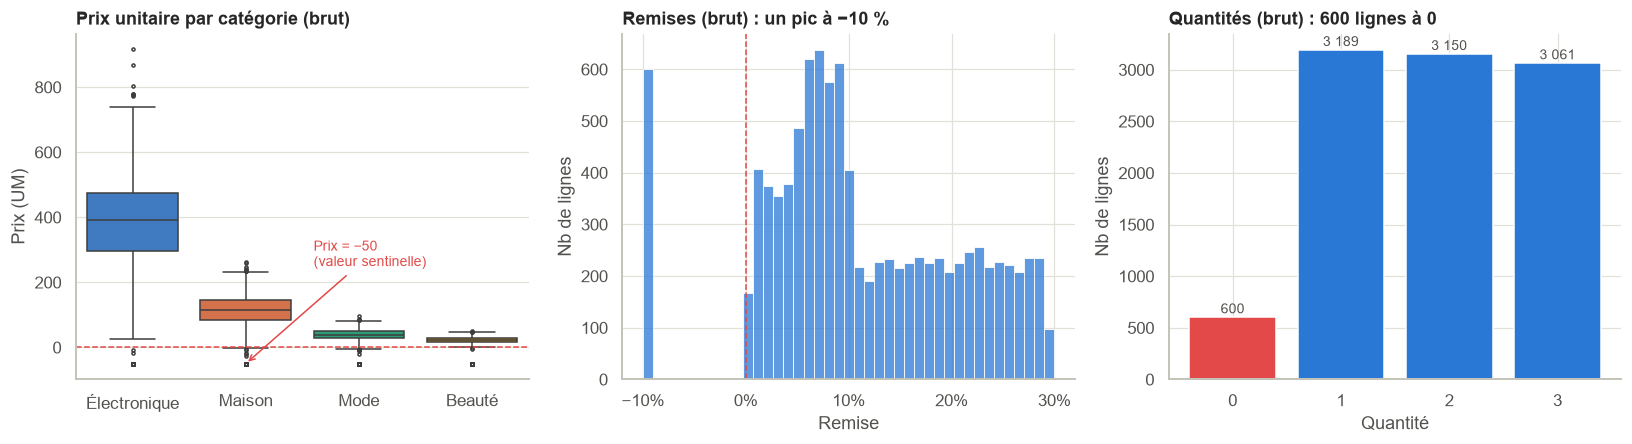

In [8]:
dd = raw.drop_duplicates().copy()
dd["cat"] = ap._categorie_du_produit(dd["nom_produit"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
# (a) prix par catégorie : le -50 saute aux yeux
sns.boxplot(data=dd, x="cat", y="prix_unitaire", order=ORDRE_CAT, palette=[C[c] for c in ORDRE_CAT], ax=axes[0], fliersize=2, linewidth=1)
axes[0].axhline(0, color=ROUGE, lw=1, ls="--"); axes[0].set_title("Prix unitaire par catégorie (brut)"); axes[0].set_xlabel(""); axes[0].set_ylabel("Prix (UM)")
axes[0].annotate("Prix = −50\n(valeur sentinelle)", xy=(1, -50), xytext=(1.6, 250), arrowprops=dict(arrowstyle="->", color=ROUGE), color=ROUGE, fontsize=9)
# (b) remises
sns.histplot(dd["remise"], bins=41, color=BLEU, ax=axes[1]); axes[1].axvline(0, color=ROUGE, lw=1, ls="--")
axes[1].set_title("Remises (brut) : un pic à −10 %"); axes[1].set_xlabel("Remise"); axes[1].set_ylabel("Nb de lignes")
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
# (c) quantités
q = dd["quantite"].value_counts().sort_index()
axes[2].bar(q.index.astype(str), q.values, color=[ROUGE if i == 0 else BLEU for i in q.index])
for i, v in zip(range(len(q)), q.values): axes[2].text(i, v + 40, nf(v), ha="center", fontsize=9, color=C["texte2"])
axes[2].set_title("Quantités (brut) : 600 lignes à 0"); axes[2].set_xlabel("Quantité"); axes[2].set_ylabel("Nb de lignes")
plt.tight_layout(); sauver(fig, "fig_audit_aberrations"); plt.show()

In [9]:
# Valeurs aberrantes « hautes » : test IQR sur les prix valides, par catégorie (méthode standard 1,5 × IQR)
v = dd[dd["prix_unitaire"] > 0]
res = []
for cat, g in v.groupby("cat"):
    q1, q3 = g["prix_unitaire"].quantile([.25, .75]); i = q3 - q1
    haut = (g["prix_unitaire"] > q3 + 1.5 * i).sum()
    res.append((cat, g["prix_unitaire"].max(), q3 + 1.5 * i, haut, haut / len(g)))
display(pd.DataFrame(res, columns=["catégorie", "prix max", "seuil IQR haut", "nb au-dessus", "part"]).set_index("catégorie"))
print("Les prix hauts sont une queue de distribution plausible (max Électronique ≈ 916 pour une médiane ≈ 360, soit ×2,5) : "
      "ils sont conservés. Seuls les prix ≤ 0 sont des erreurs.")

,prix max,seuil IQR haut,nb au-dessus,part
catégorie,,,,
Beauté,51.04,45.86,7,0.00
Maison,263.98,226.62,10,0.01
Mode,95.37,79.90,9,0.00
Électronique,915.86,725.05,9,0.00


Les prix hauts sont une queue de distribution plausible (max Électronique ≈ 916 pour une médiane ≈ 360, soit ×2,5) : ils sont conservés. Seuls les prix ≤ 0 sont des erreurs.


### 2.7 Fiabilité des clés et des champs liés au client

In [10]:
multi = dd.assign(v=ap._cle(dd["ville"]).map(ap.VILLES)).groupby("id_client")["v"].nunique() > 1
print(f"{pct(multi.mean(),0)} des clients apparaissent dans plus d'une ville -> la ville n'est pas une propriété stable du client.")
print("Décision : les analyses géographiques se font sur la ville de la COMMANDE, jamais sur une ville « du client ».")
print(f"Dates : {dd['date_commande'].min()} -> {dd['date_commande'].max()} (format ISO homogène, 6 mois pleins).")
print(f"cout_marketing : {dd['cout_marketing'].min():.2f} -> {dd['cout_marketing'].max():.2f} UM par commande (coût attribué à chaque commande, saisi parfois sous la forme « 08.04 » : lu correctement comme 8,04).")

71 % des clients apparaissent dans plus d'une ville -> la ville n'est pas une propriété stable du client.
Décision : les analyses géographiques se font sur la ville de la COMMANDE, jamais sur une ville « du client ».
Dates : 2025-07-01 -> 2025-12-31 (format ISO homogène, 6 mois pleins).
cout_marketing : 0.50 -> 19.98 UM par commande (coût attribué à chaque commande, saisi parfois sous la forme « 08.04 » : lu correctement comme 8,04).


### 2.8 Synthèse de l'audit

In [11]:
audit = ap.audit_qualite(raw)
display(audit.style.format({"% du brut": "{:.2f} %"}).hide(axis="index"))
lignes_touchees = (raw.duplicated().sum()
                   + ((dd["prix_unitaire"] <= 0) | (dd["quantite"] == 0) | (dd["remise"] < 0)).sum())
print(f"\nPlus d'une ligne sur six ({pct(lignes_touchees/len(raw),0)}) porte au moins une anomalie de saisie : les corrections ne sont pas cosmétiques.")

Problème,Lignes concernées,Traitement,% du brut
Doublons exacts (lignes entièrement identiques),100,Supprimer,0.99 %
Prix unitaire = -50 (valeur sentinelle),600,Imputer par la médiane du produit,5.94 %
Autres prix négatifs,22,Imputer par la médiane du produit,0.22 %
Quantité = 0,600,Supprimer (vente impossible),5.94 %
Remise négative (-10 %),600,Imputer par la médiane de la catégorie,5.94 %
Ville mal orthographiée (Kinshassa),600,Corriger -> Kinshasa,5.94 %
Catégorie non standard (« electronique » en minuscules),600,Uniformiser la casse,5.94 %
Catégorie contredite par le nom du produit,436,Reclasser selon le produit (source fiable),4.32 %
Statut non standard (retournée),816,Uniformiser -> Retournée,8.08 %
Valeurs manquantes (toutes colonnes),0,Aucune action,0.00 %



Plus d'une ligne sur six (18 %) porte au moins une anomalie de saisie : les corrections ne sont pas cosmétiques.


**Résumé d'audit (à retenir) :**

| # | Problème | Volume | Risque business si non traité | Décision |
|---|---|---|---|---|
| 1 | Doublons exacts | 100 | CA et commandes gonflés de 1 % | Suppression |
| 2 | Prix négatifs (−50 + 22 autres) | 622 | CA sous-estimé, marges fausses | Imputation : médiane du produit |
| 3 | Quantités nulles | 600 | « Ventes » sans produit, paniers faussés | Suppression (information irrécupérable) |
| 4 | Remises négatives (−10 %) | 600 | CA surestimé | Imputation : médiane de la catégorie |
| 5 | « Kinshassa » | 600 | Ville n°1 découpée en deux | Correction |
| 6 | « electronique » (casse) | 600 | Catégorie dédoublée | Normalisation |
| 7 | **Catégorie contredite par le produit** | **436** | **Électronique gonflée, taux de retour/marge faux** | **Reclassement d'après le produit** |
| 8 | Statut « retournée » | 816 | Retours non comptés si filtre sensible à la casse | Normalisation |

## 3. Data cleaning
Chaque étape est exécutée **explicitement** (pas de boîte noire) et son effet est compté. En fin de section, le résultat est comparé au pipeline partagé (`afrimarket_pipeline.nettoyer`) utilisé par le dashboard : les deux doivent être identiques.

In [12]:
journal = {}
df = raw.copy()
journal["Lignes brutes"] = len(df)

def normaliser(s):
    # clé de rapprochement : sans accent, minuscules, sans espaces parasites
    import unicodedata
    return s.map(lambda x: unicodedata.normalize("NFKD", str(x)).encode("ascii", "ignore").decode().strip().lower())

# 3.1 Doublons : on garde la première occurrence
n = len(df); df = df.drop_duplicates().reset_index(drop=True)
journal["Doublons supprimés"] = n - len(df)

# 3.2 Dates : texte -> datetime (format ISO strict ; toute date invalide serait détectée)
df["date_commande"] = pd.to_datetime(df["date_commande"], format="%Y-%m-%d", errors="coerce")
journal["Dates invalides"] = int(df["date_commande"].isna().sum())

# 3.3 Villes : « Kinshassa » -> « Kinshasa », casse/accents uniformisés
df["ville"] = normaliser(df["ville"]).map(ap.VILLES)

# 3.4 Statuts : Livrée / Retournée / Annulée
df["statut_commande"] = normaliser(df["statut_commande"]).map(ap.STATUTS)

# 3.5 Catégories : standardisation de la casse PUIS reclassement d'après le nom du produit (source fiable)
df["categorie"] = normaliser(df["categorie"]).map(ap.CATEGORIES)
cat_produit = normaliser(df["nom_produit"].str.split("_").str[1]).map(ap.CATEGORIES)
df["categorie_corrigee"] = df["categorie"] != cat_produit
journal["Catégories reclassées d'après le produit"] = int(df["categorie_corrigee"].sum())
df["categorie"] = cat_produit

# 3.6 Quantités nulles : suppression (on ne peut pas deviner la quantité réelle ; test de robustesse en §6)
n = len(df); df = df[df["quantite"] > 0].reset_index(drop=True)
journal["Lignes quantité = 0 supprimées"] = n - len(df)

# 3.7 Prix aberrants (≤ 0) : médiane des prix valides du MÊME produit (repli : médiane de la catégorie)
df["prix_corrige"] = df["prix_unitaire"] <= 0
med_produit = df.loc[~df["prix_corrige"]].groupby("nom_produit")["prix_unitaire"].median()
med_cat = df.loc[~df["prix_corrige"]].groupby("categorie")["prix_unitaire"].median()
prix_impute = df["nom_produit"].map(med_produit).fillna(df["categorie"].map(med_cat))
df.loc[df["prix_corrige"], "prix_unitaire"] = prix_impute[df["prix_corrige"]]
journal["Prix négatifs imputés"] = int(df["prix_corrige"].sum())

# 3.8 Remises négatives : médiane des remises valides de la catégorie
df["remise_corrigee"] = df["remise"] < 0
med_rem = df.loc[~df["remise_corrigee"]].groupby("categorie")["remise"].median()
df.loc[df["remise_corrigee"], "remise"] = df.loc[df["remise_corrigee"], "categorie"].map(med_rem)
journal["Remises négatives imputées"] = int(df["remise_corrigee"].sum())

df_clean = df.copy()
journal["Lignes dans df_clean"] = len(df_clean)
display(pd.Series(journal, name="lignes").to_frame())

,lignes
Lignes brutes,10100
Doublons supprimés,100
Dates invalides,0
Catégories reclassées d'après le produit,436
Lignes quantité = 0 supprimées,600
Prix négatifs imputés,586
Remises négatives imputées,563
Lignes dans df_clean,9400


In [13]:
# --- Contrôles de qualité APRÈS nettoyage (doivent tous être vrais) ---
controles = {
    "Aucun doublon": not df_clean.duplicated().any(),
    "id_commande unique": df_clean["id_commande"].is_unique,
    "Aucun prix <= 0": (df_clean["prix_unitaire"] > 0).all(),
    "Aucune quantité <= 0": (df_clean["quantite"] > 0).all(),
    "Remises dans [0 ; 30 %]": df_clean["remise"].between(0, 0.30).all(),
    "8 villes": df_clean["ville"].nunique() == 8,
    "4 catégories": df_clean["categorie"].nunique() == 4,
    "3 statuts": df_clean["statut_commande"].nunique() == 3,
    "Dates dans la période": df_clean["date_commande"].between("2025-07-01", "2025-12-31").all(),
    "Chaque produit dans 1 seule catégorie": (df_clean.groupby("nom_produit")["categorie"].nunique() == 1).all(),
    "Aucune valeur manquante": not df_clean[raw.columns].isna().any().any(),
}
display(pd.Series(controles, name="OK ?").to_frame())
assert all(controles.values()), "Un contrôle de qualité a échoué"

# --- Cohérence avec le pipeline partagé (dashboard) ---
ref, _ = ap.nettoyer(raw)
pd.testing.assert_frame_equal(df_clean.sort_values("id_commande").reset_index(drop=True)[sorted(df_clean.columns)],
                              ref.sort_values("id_commande").reset_index(drop=True)[sorted(ref.columns)], check_dtype=False)
print("OK - df_clean est strictement identique au pipeline partagé.")

# Prix : avant/après sur les lignes corrigées
avant = raw.drop_duplicates().set_index("id_commande").loc[df_clean.loc[df_clean["prix_corrige"], "id_commande"], "prix_unitaire"]
print(f"Prix corrigés : {len(avant)} lignes, de {avant.median():.0f} (médiane brute) à "
      f"{df_clean.loc[df_clean['prix_corrige'], 'prix_unitaire'].median():.0f} (médiane après imputation).")

,OK ?
Aucun doublon,True
id_commande unique,True
Aucun prix <= 0,True
Aucune quantité <= 0,True
Remises dans [0 ; 30 %],True
8 villes,True
4 catégories,True
3 statuts,True
Dates dans la période,True
Chaque produit dans 1 seule catégorie,True


OK - df_clean est strictement identique au pipeline partagé.
Prix corrigés : 586 lignes, de -50 (médiane brute) à 44 (médiane après imputation).


## 4. Feature engineering
Variables créées (définitions au §1) : `chiffre_affaires`, `ca_net`, `marge_brute`, `profit_net`, `mois`, `indicateur_retour`, `nombre_commandes_par_client`, `valeur_vie_client` (CLV simplifiée = profit net cumulé par client sur la période), ainsi que `cout_achat`, `cout_livraison_effectif`, `indicateur_annulation`.

**CLV simplifiée :** profit net cumulé du client sur les 6 mois (valeur historique observée, sans actualisation ni projection : on ne prétend pas prédire l'avenir avec 6 mois de recul).

In [14]:
df = ap.ajouter_features(df_clean)      # hypothèses de coût d'achat : voir §1
clients = ap.table_clients(df)

# Contrôle comptable : le profit net doit se réconcilier ligne à ligne
ecart = (df["profit_net"] - (df["ca_net"] - df["cout_achat"] - df["cout_livraison_effectif"] - df["cout_marketing"])).abs().max()
assert ecart < 1e-9, ecart
print(f"Contrôle comptable OK (écart max {ecart:.1e}).")

# Export : df_clean (nettoyage seul) et df_analyse (nettoyage + features), réutilisables hors du notebook
os.makedirs(ap.CLEAN_DIR, exist_ok=True)
df_clean.to_csv(os.path.join(ap.CLEAN_DIR, "df_clean.csv"), index=False, encoding="utf-8-sig")
df.to_csv(os.path.join(ap.CLEAN_DIR, "df_analyse.csv"), index=False, encoding="utf-8-sig")
print(f"Exportés dans data/clean/ : df_clean.csv ({len(df_clean):,} lignes) et df_analyse.csv ({df.shape[1]} colonnes).".replace(",", " "))

nouvelles = ["mois", "chiffre_affaires", "ca_net", "cout_achat", "marge_brute", "cout_livraison_effectif",
             "profit_net", "indicateur_retour", "indicateur_annulation", "nombre_commandes_par_client", "valeur_vie_client"]
display(df[["id_commande", "categorie", "statut_commande"] + nouvelles].head(6))

Contrôle comptable OK (écart max 0.0e+00).


Exportés dans data/clean/ : df_clean.csv (9 400 lignes) et df_analyse.csv (31 colonnes).


,id_commande,categorie,statut_commande,mois,chiffre_affaires,ca_net,cout_achat,marge_brute,cout_livraison_effectif,profit_net,indicateur_retour,indicateur_annulation,nombre_commandes_par_client,valeur_vie_client
0,CMD100000,Mode,Livrée,2025-12-01,138.72,138.72,67.12,71.60,2.45,68.15,0,0,25,"1,525.07"
1,CMD100001,Beauté,Livrée,2025-07-01,66.92,66.92,26.03,40.90,6.89,25.97,0,0,4,139.80
2,CMD100004,Électronique,Livrée,2025-11-01,977.47,977.47,718.14,259.33,5.16,253.62,0,0,26,"1,365.64"
3,CMD100005,Maison,Livrée,2025-10-01,192.16,192.16,117.43,74.73,8.63,60.65,0,0,16,842.65
4,CMD100006,Mode,Livrée,2025-07-01,56.68,56.68,31.10,25.57,3.59,12.75,0,0,16,360.02
5,CMD100007,Beauté,Livrée,2025-10-01,67.29,67.29,27.38,39.90,2.51,31.23,0,0,21,"1,382.15"


## 5. Analyses

### 5.1 Performance globale

In [15]:
kp = ap.kpis_globaux(df)
cartes = pd.DataFrame({
    "Indicateur": ["Chiffre d'affaires net (livré)", "Profit net estimé", "Marge brute estimée", "Panier moyen (commande livrée)",
                   "Taux d'annulation", "Taux de retour", "Coût marketing total", "CA remboursé (retours)", "Commandes analysées", "Clients acheteurs"],
    "Valeur": [f"{nf(kp['ca_total'])} UM", f"{nf(kp['profit_net'])} UM  ({pct(kp['profit_net']/kp['ca_total'])} du CA)",
               f"{nf(kp['marge_brute'])} UM  ({pct(kp['marge_brute']/kp['ca_total'])} du CA)", f"{nf(kp['panier_moyen'],1)} UM",
               pct(kp["taux_annulation"]), pct(kp["taux_retour"]), f"{nf(kp['cout_marketing'])} UM  ({pct(kp['cout_marketing']/kp['ca_total'])} du CA)",
               f"{nf(kp['ca_perdu_retour'])} UM  ({pct(kp['ca_perdu_retour']/(kp['ca_total']+kp['ca_perdu_retour']))} du CA livré+retourné)",
               nf(kp["nb_commandes"]), nf(kp["nb_clients"])],
}).set_index("Indicateur")
display(cartes)

,Valeur
Indicateur,
Chiffre d'affaires net (livré),2 183 205 UM
Profit net estimé,"460 831 UM (21,1 % du CA)"
Marge brute estimée,"590 310 UM (27,0 % du CA)"
Panier moyen (commande livrée),"258,3 UM"
Taux d'annulation,"1,9 %"
Taux de retour,"8,3 %"
Coût marketing total,"69 505 UM (3,2 % du CA)"
CA remboursé (retours),"318 655 UM (12,7 % du CA livré+retourné)"
Commandes analysées,9 400


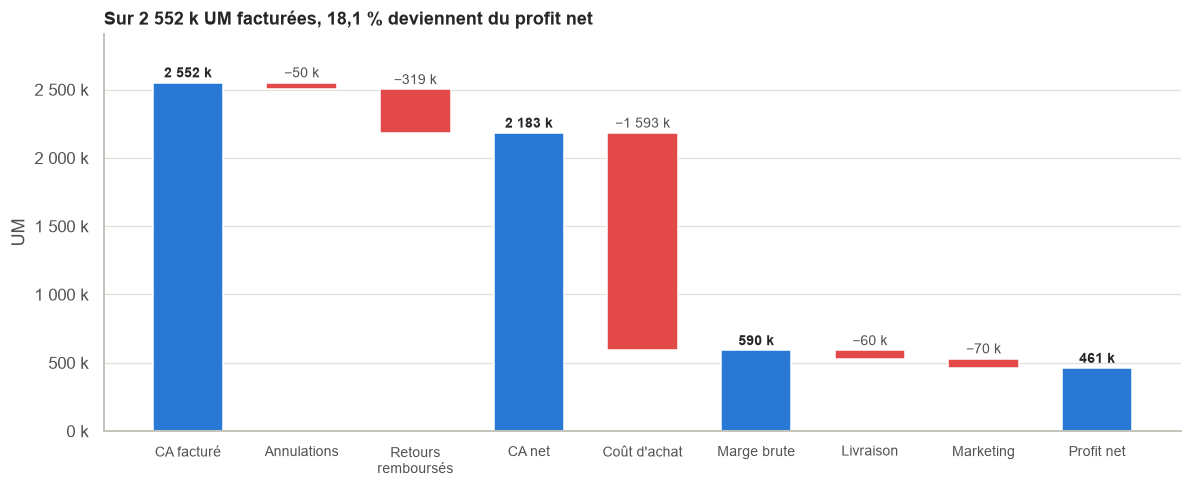

In [16]:
# De la vente facturée au profit : où part l'argent ? (cascade)
ca_fact = df["chiffre_affaires"].sum()
etapes = [("CA facturé", ca_fact, "total"), ("Annulations", -df["ca_perdu_annulation"].sum(), "neg"), ("Retours\nremboursés", -df["ca_perdu_retour"].sum(), "neg"),
          ("CA net", None, "total"), ("Coût d'achat", -df["cout_achat"].sum(), "neg"), ("Marge brute", None, "total"),
          ("Livraison", -df["cout_livraison_effectif"].sum(), "neg"), ("Marketing", -df["cout_marketing"].sum(), "neg"), ("Profit net", None, "total")]
fig, ax = plt.subplots(figsize=(11, 4.6))
cum = 0
for i, (lab, val, typ) in enumerate(etapes):
    if typ == "total":
        if val is not None: cum = val
        ax.bar(i, cum, color=BLEU, width=.62); ax.text(i, cum + ca_fact*.015, k(cum), ha="center", fontsize=9, fontweight="bold")
    else:
        ax.bar(i, val, bottom=cum, color=ROUGE, width=.62); ax.text(i, cum + ca_fact*.015, "−" + k(-val), ha="center", fontsize=9, color=C["texte2"])
        cum += val
ax.set_xticks(range(len(etapes))); ax.set_xticklabels([e[0] for e in etapes], fontsize=9)
ax.yaxis.set_major_formatter(fmt_k); ax.set_ylabel("UM"); ax.grid(axis="x", visible=False); ax.set_ylim(0, ca_fact*1.14)
ax.set_title(f"Sur {k(ca_fact)} UM facturées, {pct(kp['profit_net']/ca_fact)} deviennent du profit net")
plt.tight_layout(); sauver(fig, "fig_cascade"); plt.show()

,ca,profit,commandes,croissance,taux_profit
mois_label,,,,,
2025-07,"347,380","71,177",1513,+nan%,20.5%
2025-08,"368,752","76,952",1579,+6.2%,20.9%
2025-09,"344,425","70,060",1468,-6.6%,20.3%
2025-10,"373,973","76,846",1617,+8.6%,20.5%
2025-11,"335,904","73,675",1524,-10.2%,21.9%
2025-12,"412,771","92,122",1699,+22.9%,22.3%


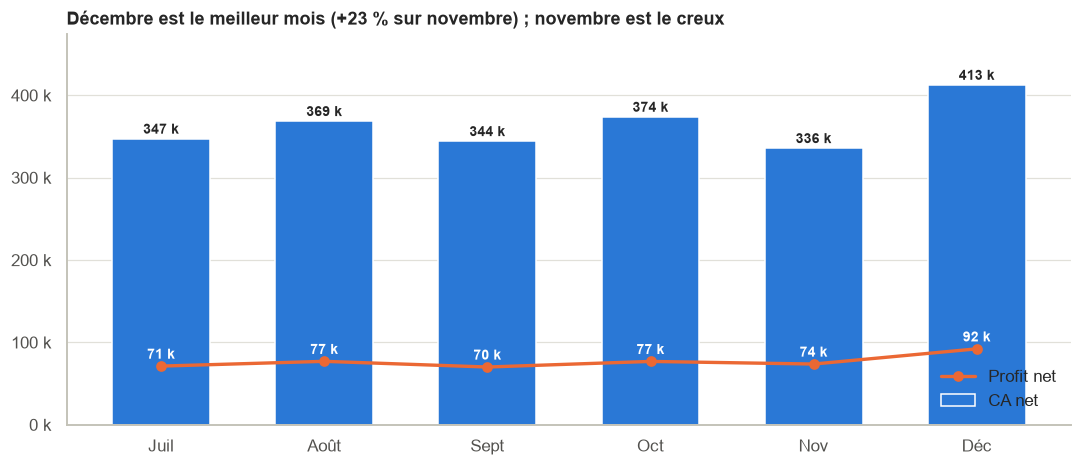

In [17]:
# Évolution mensuelle : CA net, profit net et dynamique de croissance
m = df.groupby("mois_label").agg(ca=("ca_net", "sum"), profit=("profit_net", "sum"), commandes=("id_commande", "count"))
m["croissance"] = m["ca"].pct_change()
m["taux_profit"] = m["profit"] / m["ca"]
display(m.style.format({"ca": "{:,.0f}", "profit": "{:,.0f}", "croissance": "{:+.1%}", "taux_profit": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(10, 4.4))
x = np.arange(len(m)); ax.bar(x, m["ca"], color=BLEU, width=.6, label="CA net")
ax.plot(x, m["profit"], color=ORANGE, marker="o", lw=2.2, label="Profit net")
for i, (a, b) in enumerate(zip(m["ca"], m["profit"])):
    ax.text(i, a + 6000, k(a), ha="center", fontsize=9, fontweight="bold"); ax.text(i, b + 9000, k(b), ha="center", fontsize=9, color="white", fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels([MOIS_FR[i] for i in m.index]); ax.yaxis.set_major_formatter(fmt_k); ax.set_ylim(0, m["ca"].max()*1.15)
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="x", visible=False)
ax.set_title("Décembre est le meilleur mois (+23 % sur novembre) ; novembre est le creux")
plt.tight_layout(); sauver(fig, "fig_mensuel"); plt.show()

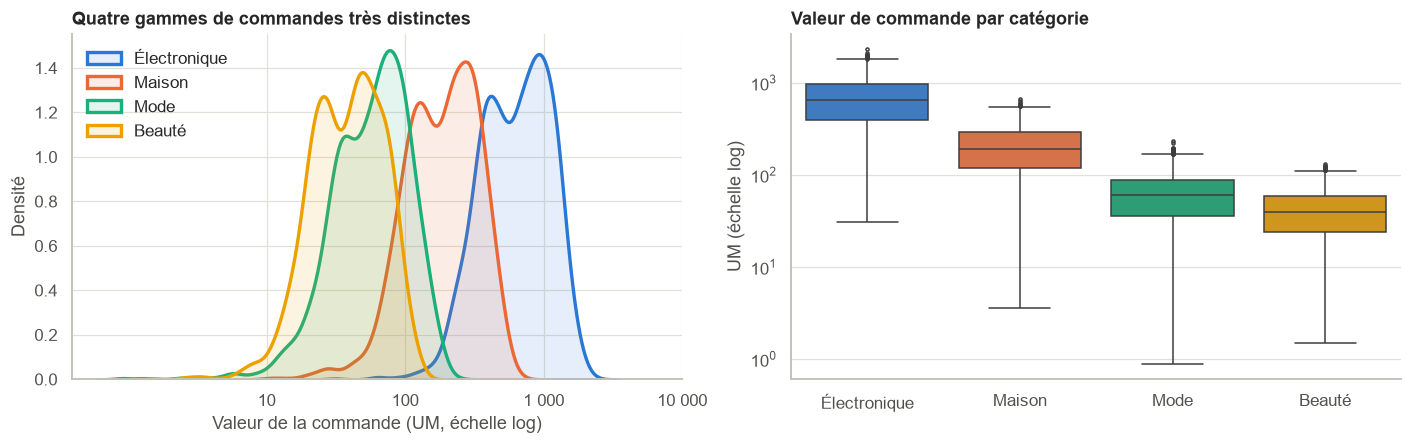

In [18]:
# Distribution de la valeur des commandes livrées (échelle log : 4 gammes de prix très différentes)
liv = df[df["statut_commande"] == "Livrée"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for cat in ORDRE_CAT:
    sns.kdeplot(np.log10(liv.loc[liv["categorie"] == cat, "ca_net"]), ax=axes[0], color=C[cat], lw=2.2, label=cat, fill=True, alpha=.12)
axes[0].set_xticks([1, 2, 3, 4]); axes[0].set_xticklabels(["10", "100", "1 000", "10 000"]); axes[0].legend(frameon=False)
axes[0].set_xlabel("Valeur de la commande (UM, échelle log)"); axes[0].set_ylabel("Densité"); axes[0].set_title("Quatre gammes de commandes très distinctes")
sns.boxplot(data=liv, x="categorie", y="ca_net", order=ORDRE_CAT, palette=[C[c] for c in ORDRE_CAT], ax=axes[1], fliersize=2, linewidth=1)
axes[1].set_yscale("log"); axes[1].set_xlabel(""); axes[1].set_ylabel("UM (échelle log)"); axes[1].set_title("Valeur de commande par catégorie")
plt.tight_layout(); plt.show()

In [19]:
display(Markdown(f'''
**Lecture business — performance globale**
- **{nf(kp['ca_total'])} UM** de CA net pour **{nf(kp['profit_net'])} UM** de profit net (**{pct(kp['profit_net']/kp['ca_total'])}**). La rentabilité est correcte mais fragile : le marketing coûte {pct(kp['cout_marketing']/kp['ca_total'])} du CA et les retours en font disparaître **{k(kp['ca_perdu_retour'])} UM**.
- Les **annulations** sont faibles au global ({pct(kp['taux_annulation'])}) mais ce chiffre **masque un problème localisé** (voir 5.3). Les **retours** ({pct(kp['taux_retour'])}) sont un vrai sujet : ils pèsent plus que les annulations ({k(kp['ca_perdu_retour'])} contre {k(df['ca_perdu_annulation'].sum())} UM) et sont concentrés sur une catégorie (voir 5.2).
- L'activité est **stable puis accélère en décembre** ; novembre est le creux, ce qui cache une bascule de mix (Maison ↑, Mode/Électronique ↓).
'''))


**Lecture business — performance globale**
- **2 183 205 UM** de CA net pour **460 831 UM** de profit net (**21,1 %**). La rentabilité est correcte mais fragile : le marketing coûte 3,2 % du CA et les retours en font disparaître **319 k UM**.
- Les **annulations** sont faibles au global (1,9 %) mais ce chiffre **masque un problème localisé** (voir 5.3). Les **retours** (8,3 %) sont un vrai sujet : ils pèsent plus que les annulations (319 k contre 50 k UM) et sont concentrés sur une catégorie (voir 5.2).
- L'activité est **stable puis accélère en décembre** ; novembre est le creux, ce qui cache une bascule de mix (Maison ↑, Mode/Électronique ↓).


### 5.2 Analyse par catégorie
**Question stratégique : quelle catégorie doit être priorisée ou optimisée ?**

In [20]:
cat = ap.agg_dimension(df, "categorie").loc[ORDRE_CAT]
cat["part_ca"] = cat["ca_net"] / cat["ca_net"].sum()
cat["part_profit"] = cat["profit_net"] / cat["profit_net"].sum()
cat["croissance_t4_t3"] = ap.croissance_t4_t3(df, "categorie")
cat["ca_rembourse_retours"] = df.groupby("categorie")["ca_perdu_retour"].sum()
tab = cat[["commandes", "ca_net", "part_ca", "marge_brute", "taux_marge", "profit_net", "taux_profit", "part_profit", "panier_moyen", "taux_retour", "croissance_t4_t3"]]
display(tab.style.format({"commandes": "{:,.0f}", "ca_net": "{:,.0f}", "part_ca": "{:.1%}", "marge_brute": "{:,.0f}", "taux_marge": "{:.1%}", "profit_net": "{:,.0f}",
                          "taux_profit": "{:.1%}", "part_profit": "{:.1%}", "panier_moyen": "{:,.0f}", "taux_retour": "{:.1%}", "croissance_t4_t3": "{:+.1%}"}))

,commandes,ca_net,part_ca,marge_brute,taux_marge,profit_net,taux_profit,part_profit,panier_moyen,taux_retour,croissance_t4_t3
categorie,,,,,,,,,,,
Électronique,"2,597","1,544,795",70.8%,"312,789",20.2%,"276,219",17.9%,59.9%,719,15.6%,-2.5%
Maison,"1,916","377,968",17.3%,"147,025",38.9%,"121,080",32.0%,26.3%,212,5.0%,+67.7%
Mode,"3,000","180,890",8.3%,"81,866",45.3%,"40,607",22.4%,8.8%,66,7.5%,-17.0%
Beauté,"1,887","79,551",3.6%,"48,631",61.1%,"22,925",28.8%,5.0%,44,2.9%,+7.2%


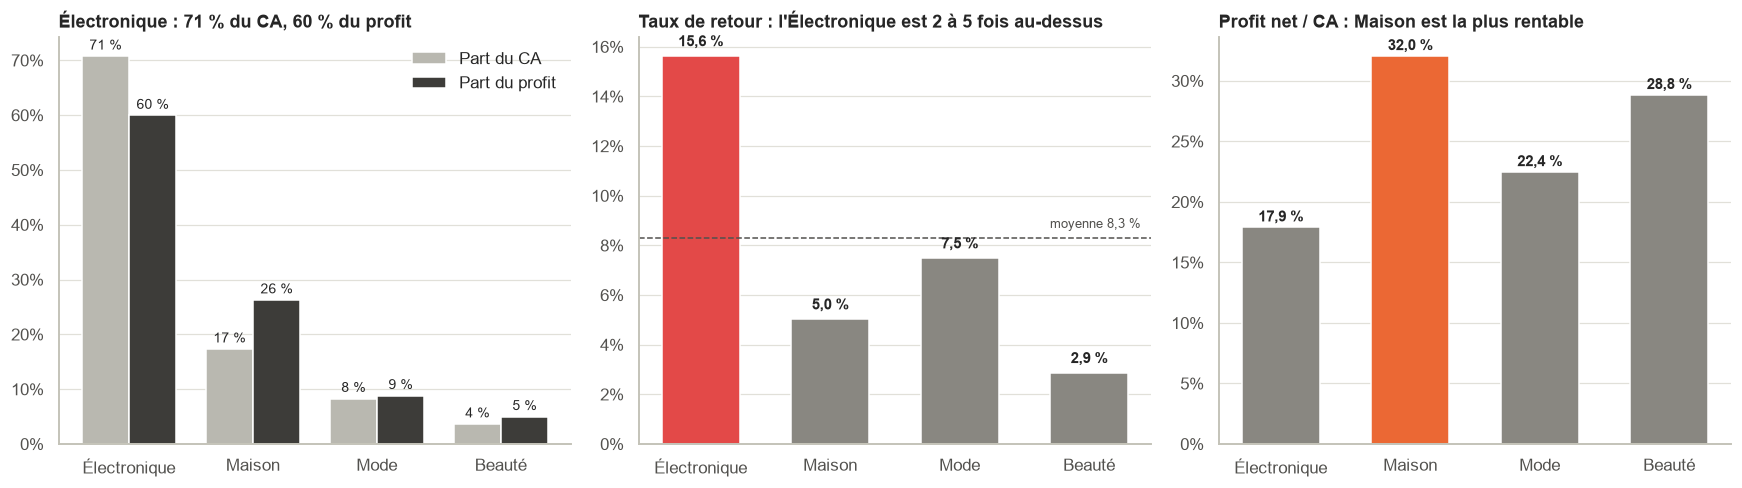

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
# (a) CA vs profit : part de chaque catégorie
x = np.arange(4); w = .38
axes[0].bar(x - w/2, cat["part_ca"], w, color=MES1, label="Part du CA"); axes[0].bar(x + w/2, cat["part_profit"], w, color=MES2, label="Part du profit")
for i, (a, b) in enumerate(zip(cat["part_ca"], cat["part_profit"])):
    axes[0].text(i - w/2, a + .012, f"{pct(a,0)}", ha="center", fontsize=9); axes[0].text(i + w/2, b + .012, f"{pct(b,0)}", ha="center", fontsize=9)
axes[0].set_xticks(x); axes[0].set_xticklabels(ORDRE_CAT); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); axes[0].legend(frameon=False)
axes[0].set_title("Électronique : 71 % du CA, 60 % du profit"); axes[0].grid(axis="x", visible=False)
# (b) taux de retour
cols = [ROUGE if c == "Électronique" else GRIS for c in ORDRE_CAT]
axes[1].bar(ORDRE_CAT, cat["taux_retour"], color=cols, width=.6)
for i, v in enumerate(cat["taux_retour"]): axes[1].text(i, v + .004, pct(v), ha="center", fontsize=10, fontweight="bold")
axes[1].axhline(kp["taux_retour"], color=C["texte2"], ls="--", lw=1); axes[1].text(3.4, kp["taux_retour"] + .004, f"moyenne {pct(kp['taux_retour'])}", ha="right", fontsize=8.5, color=C["texte2"])
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); axes[1].set_title("Taux de retour : l'Électronique est 2 à 5 fois au-dessus"); axes[1].grid(axis="x", visible=False)
# (c) taux de profit
axes[2].bar(ORDRE_CAT, cat["taux_profit"], color=[C["Maison"] if c == "Maison" else GRIS for c in ORDRE_CAT], width=.6)
for i, v in enumerate(cat["taux_profit"]): axes[2].text(i, v + .005, pct(v), ha="center", fontsize=10, fontweight="bold")
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); axes[2].set_title("Profit net / CA : Maison est la plus rentable"); axes[2].grid(axis="x", visible=False)
plt.tight_layout(); sauver(fig, "fig_categories"); plt.show()

**Évolution mensuelle par catégorie** (interactif : survolez les courbes)

In [22]:
pm = df.pivot_table(index="mois_label", columns="categorie", values="ca_net", aggfunc="sum")[ORDRE_CAT]
pm.index = [MOIS_FR[i] for i in pm.index]
figp = px.line(pm.reset_index().melt(id_vars="index", var_name="Catégorie", value_name="CA net"), x="index", y="CA net", color="Catégorie", markers=True,
               color_discrete_map={c: C[c] for c in ORDRE_CAT}, labels={"index": ""}, title="CA net mensuel par catégorie")
figp.update_traces(line=dict(width=3), marker=dict(size=8)); figp.update_layout(height=420, hovermode="x unified", legend_title_text="")
figp.update_yaxes(tickformat=",.0f")
figp.show()

# Même chose sans l'Électronique, pour voir les mouvements des 3 autres (échelle différente -> deuxième graphique, pas d'axe double)
figp2 = px.line(pm.drop(columns="Électronique").reset_index().melt(id_vars="index", var_name="Catégorie", value_name="CA net"), x="index", y="CA net", color="Catégorie",
                markers=True, color_discrete_map={c: C[c] for c in ORDRE_CAT}, labels={"index": ""}, title="Zoom hors Électronique : Maison double en novembre, Mode chute")
figp2.update_traces(line=dict(width=3), marker=dict(size=8)); figp2.update_layout(height=380, hovermode="x unified", legend_title_text="")
figp2.show()

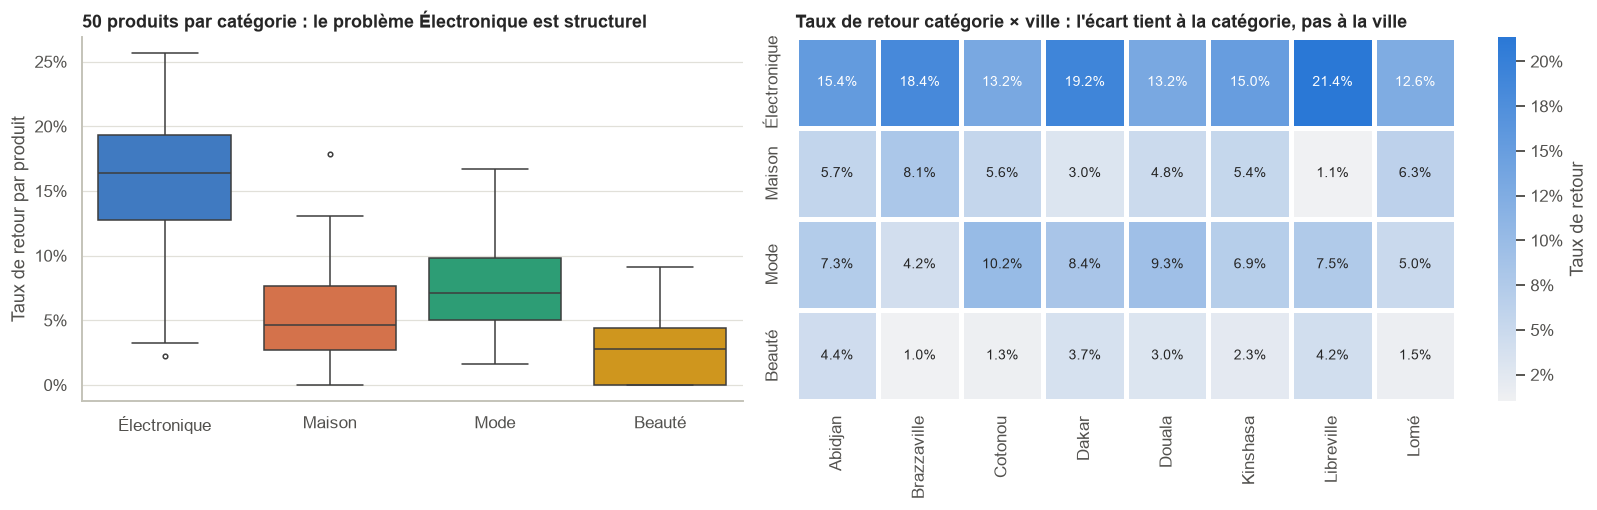

Électronique : 9 produits sur 50 dépassent 20 % de retours ; 44 sur 50 dépassent 10 %. Aucun n'est sous 2 %.


,categorie,nom_produit,commandes,taux_retour,CA net
0,Électronique,Produit_Électronique_18,39,25.6%,"18,744.00"
1,Électronique,Produit_Électronique_22,57,24.6%,"31,750.00"
2,Électronique,Produit_Électronique_10,45,24.4%,"23,641.00"
3,Électronique,Produit_Électronique_8,59,22.0%,"33,849.00"
4,Électronique,Produit_Électronique_15,47,21.3%,"26,901.00"
5,Électronique,Produit_Électronique_44,52,21.2%,"32,012.00"
6,Électronique,Produit_Électronique_9,65,20.0%,"40,769.00"
7,Électronique,Produit_Électronique_45,60,20.0%,"33,407.00"


In [23]:
# Retours : par produit (est-ce un problème de quelques produits ou structurel ?) et par ville
exp = df[df["statut_commande"] != "Annulée"]
prod = exp.groupby(["categorie", "nom_produit"]).agg(n=("id_commande", "count"), taux_retour=("indicateur_retour", "mean"), ca=("ca_net", "sum")).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
sns.boxplot(data=prod, x="categorie", y="taux_retour", order=ORDRE_CAT, palette=[C[c] for c in ORDRE_CAT], ax=axes[0], fliersize=3, linewidth=1)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); axes[0].set_xlabel(""); axes[0].set_ylabel("Taux de retour par produit")
axes[0].set_title("50 produits par catégorie : le problème Électronique est structurel")
hm = exp.pivot_table(index="categorie", columns="ville", values="indicateur_retour", aggfunc="mean").loc[ORDRE_CAT]
sns.heatmap(hm, annot=True, fmt=".1%", cmap=sns.light_palette(BLEU, as_cmap=True), cbar_kws={"label": "Taux de retour", "format": mtick.PercentFormatter(1, decimals=0)}, linewidths=2, linecolor="white", ax=axes[1], annot_kws={"fontsize": 9})
axes[1].set_title("Taux de retour catégorie × ville : l'écart tient à la catégorie, pas à la ville"); axes[1].set_xlabel(""); axes[1].set_ylabel(""); axes[1].grid(False)
plt.tight_layout(); plt.show()

el = prod[prod["categorie"] == "Électronique"].sort_values("taux_retour", ascending=False)
print(f"Électronique : {int((el['taux_retour'] >= .20).sum())} produits sur 50 dépassent 20 % de retours ; "
      f"{int((el['taux_retour'] >= .10).sum())} sur 50 dépassent 10 %. Aucun n'est sous 2 %.")
display(el.head(8).assign(taux_retour=lambda d: d["taux_retour"].map("{:.1%}".format), ca=lambda d: d["ca"].round(0)).rename(columns={"n": "commandes", "ca": "CA net"}).reset_index(drop=True))

In [24]:
c = cat
rap = ap.chiffrer_recommandations(df, clients)
display(Markdown(f'''
**Lecture business — catégories**
- **Électronique = le pilier et le point de fragilité.** {pct(c.loc['Électronique','part_ca'],0)} du CA et {pct(c.loc['Électronique','part_profit'],0)} du profit, mais **{pct(c.loc['Électronique','taux_retour'])} de retours** (Maison {pct(c.loc['Maison','taux_retour'])}, Mode {pct(c.loc['Mode','taux_retour'])}, Beauté {pct(c.loc['Beauté','taux_retour'])}) : {k(c.loc['Électronique','ca_rembourse_retours'])} UM remboursées, soit **{pct(c.loc['Électronique','ca_rembourse_retours']/df['ca_perdu_retour'].sum(),0)} de tous les retours**. Le problème est **structurel** (touche les 50 produits et toutes les villes), donc lié au sourcing, à la qualité ou à la description produit, pas à un produit isolé.
- **Maison = le relais de croissance.** Taux de profit de **{pct(c.loc['Maison','taux_profit'])}** (vs {pct(c.loc['Électronique','taux_profit'])} pour l'Électronique), retours faibles ({pct(c.loc['Maison','taux_retour'])}), et un **CA T4 en hausse de {pcs(c.loc['Maison','croissance_t4_t3'])}** sur T3 (volume de commandes ×2 dès novembre, remises inchangées : c'est de la demande, pas de la promotion).
- **Mode = à redresser.** Profit/CA de {pct(c.loc['Mode','taux_profit'])} mais **{pcs(c.loc['Mode','croissance_t4_t3'])} au T4** : la catégorie décroche à partir de novembre (probable cannibalisation par Maison en fin d'année ou rupture d'offre).
- **Beauté = niche rentable mais anecdotique** ({pct(c.loc['Beauté','part_ca'])} du CA ; marge brute la plus haute, {pct(c.loc['Beauté','taux_marge'],0)}, mais panier de {nf(c.loc['Beauté','panier_moyen'])} UM ne couvre pas bien livraison + marketing) : utile en **produit d'appoint** pour relever le panier.

> **Réponse à la question stratégique.** **Optimiser l'Électronique** (réduire les retours : levier n°1 de profit) et **prioriser Maison** (marge et croissance). Redresser Mode ; garder Beauté en complément.
'''))


**Lecture business — catégories**
- **Électronique = le pilier et le point de fragilité.** 71 % du CA et 60 % du profit, mais **15,6 % de retours** (Maison 5,0 %, Mode 7,5 %, Beauté 2,9 %) : 282 k UM remboursées, soit **88 % de tous les retours**. Le problème est **structurel** (touche les 50 produits et toutes les villes), donc lié au sourcing, à la qualité ou à la description produit, pas à un produit isolé.
- **Maison = le relais de croissance.** Taux de profit de **32,0 %** (vs 17,9 % pour l'Électronique), retours faibles (5,0 %), et un **CA T4 en hausse de +68 %** sur T3 (volume de commandes ×2 dès novembre, remises inchangées : c'est de la demande, pas de la promotion).
- **Mode = à redresser.** Profit/CA de 22,4 % mais **-17 % au T4** : la catégorie décroche à partir de novembre (probable cannibalisation par Maison en fin d'année ou rupture d'offre).
- **Beauté = niche rentable mais anecdotique** (3,6 % du CA ; marge brute la plus haute, 61 %, mais panier de 44 UM ne couvre pas bien livraison + marketing) : utile en **produit d'appoint** pour relever le panier.

> **Réponse à la question stratégique.** **Optimiser l'Électronique** (réduire les retours : levier n°1 de profit) et **prioriser Maison** (marge et croissance). Redresser Mode ; garder Beauté en complément.


### 5.3 Analyse géographique
**Question stratégique : où devons-nous investir davantage ?**

In [25]:
vil = ap.agg_dimension(df, "ville").sort_values("ca_net", ascending=False)
vil["part_ca"] = vil["ca_net"] / vil["ca_net"].sum()
vil["croissance_t4_t3"] = ap.croissance_t4_t3(df, "ville")
vil["ca_annule"] = df.groupby("ville")["ca_perdu_annulation"].sum()
display(vil[["commandes", "ca_net", "part_ca", "profit_net", "taux_profit", "panier_moyen", "taux_annulation", "taux_retour", "croissance_t4_t3"]]
        .style.format({"commandes": "{:,.0f}", "ca_net": "{:,.0f}", "part_ca": "{:.1%}", "profit_net": "{:,.0f}", "taux_profit": "{:.1%}", "panier_moyen": "{:,.0f}",
                       "taux_annulation": "{:.1%}", "taux_retour": "{:.1%}", "croissance_t4_t3": "{:+.1%}"}))

,commandes,ca_net,part_ca,profit_net,taux_profit,panier_moyen,taux_annulation,taux_retour,croissance_t4_t3
ville,,,,,,,,,
Kinshasa,"2,724","660,732",30.3%,"139,967",21.2%,264,0.3%,8.0%,+4.9%
Abidjan,"1,756","434,008",19.9%,"90,179",20.8%,271,0.0%,8.7%,-1.4%
Dakar,"1,346","299,524",13.7%,"64,321",21.5%,245,0.0%,9.1%,-7.2%
Douala,"1,362","290,414",13.3%,"60,494",20.8%,267,12.9%,8.3%,+20.8%
Lomé,682,"165,054",7.6%,"34,198",20.7%,259,0.0%,6.6%,+6.3%
Cotonou,631,"142,776",6.5%,"31,038",21.7%,246,0.0%,7.9%,+33.8%
Libreville,467,"99,339",4.6%,"21,272",21.4%,235,0.0%,9.4%,+12.7%
Brazzaville,432,"91,358",4.2%,"19,362",21.2%,230,0.0%,7.9%,+4.1%


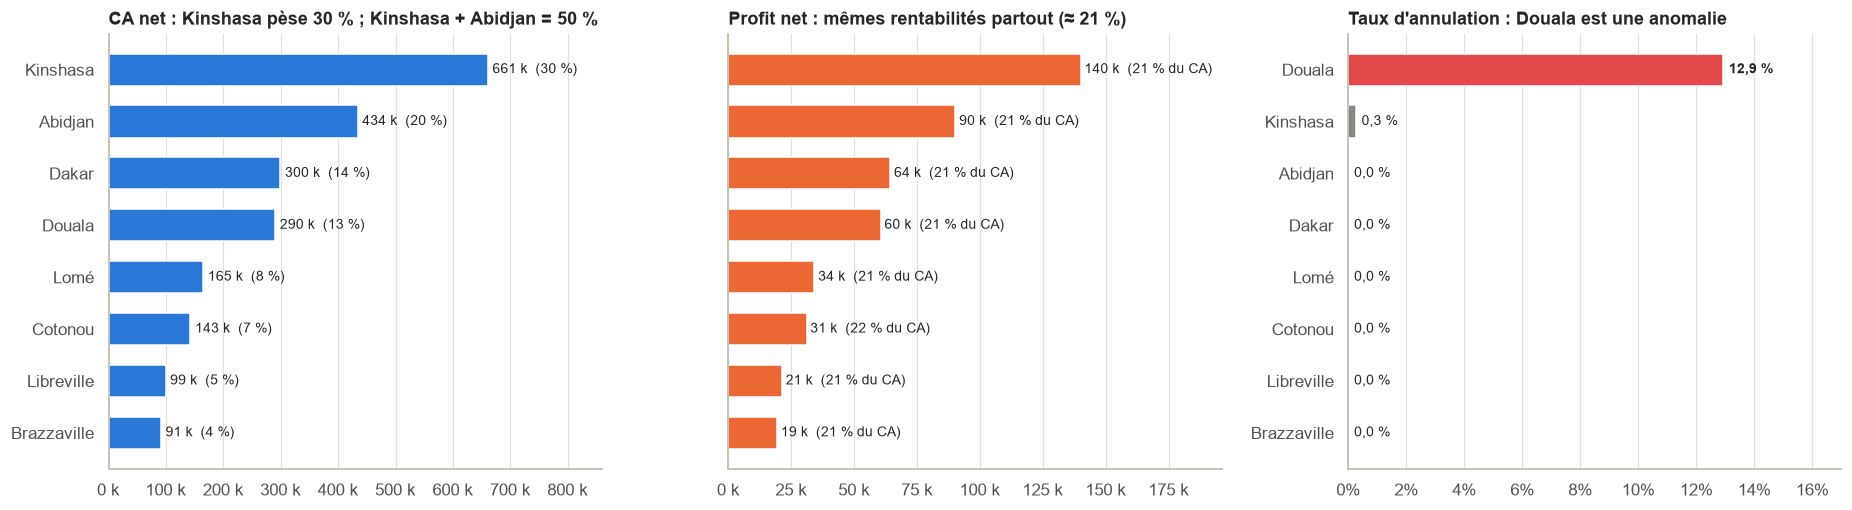

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ordre = vil.index.tolist()
axes[0].barh(ordre[::-1], vil["ca_net"][::-1], color=BLEU, height=.62)
for i, (v, p) in enumerate(zip(vil["ca_net"][::-1], vil["part_ca"][::-1])): axes[0].text(v + 8000, i, f"{k(v)}  ({pct(p,0)})", va="center", fontsize=9)
axes[0].xaxis.set_major_formatter(fmt_k); axes[0].set_xlim(0, vil["ca_net"].max()*1.3); axes[0].set_title("CA net : Kinshasa pèse 30 % ; Kinshasa + Abidjan = 50 %"); axes[0].grid(axis="y", visible=False)

axes[1].barh(ordre[::-1], vil["profit_net"][::-1], color=ORANGE, height=.62)
for i, (v, t) in enumerate(zip(vil["profit_net"][::-1], vil["taux_profit"][::-1])): axes[1].text(v + 1500, i, f"{k(v)}  ({pct(t,0)} du CA)", va="center", fontsize=9)
axes[1].xaxis.set_major_formatter(fmt_k); axes[1].set_xlim(0, vil["profit_net"].max()*1.4); axes[1].set_title("Profit net : mêmes rentabilités partout (≈ 21 %)"); axes[1].set_yticklabels([]); axes[1].grid(axis="y", visible=False)

ann = vil["taux_annulation"].sort_values(ascending=False)
axes[2].barh(ann.index[::-1], ann.values[::-1], color=[ROUGE if v > .05 else GRIS for v in ann.values[::-1]], height=.62)
for i, v in enumerate(ann.values[::-1]): axes[2].text(v + .002, i, pct(v), va="center", fontsize=9, fontweight="bold" if v > .05 else None)
axes[2].xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); axes[2].set_xlim(0, .17); axes[2].set_title("Taux d'annulation : Douala est une anomalie"); axes[2].grid(axis="y", visible=False)
plt.tight_layout(); sauver(fig, "fig_villes"); plt.show()

**Croissance mensuelle par ville** (mois sur mois ; bleu = hausse, rouge = baisse)

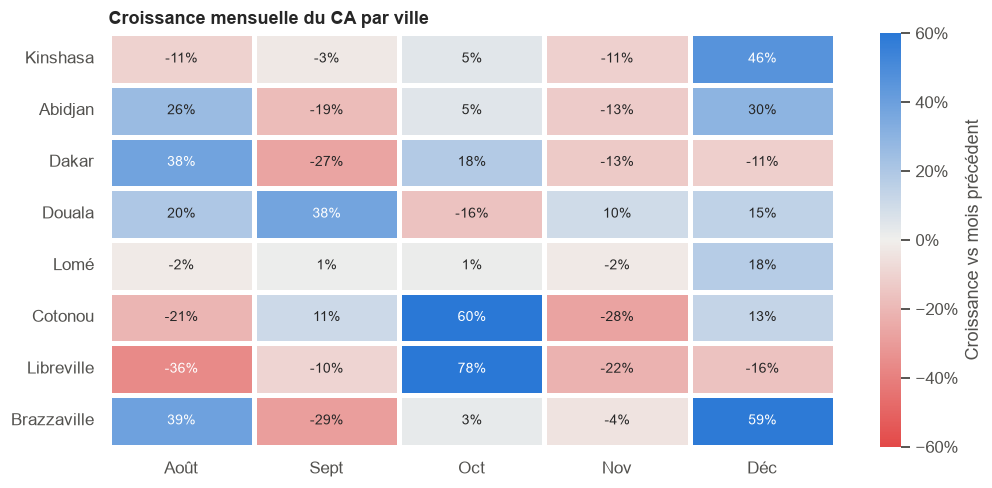

Les petites villes sont très volatiles (± 30-60 % d'un mois à l'autre) : on juge la tendance sur T4 vs T3 (trimestres), plus robuste.


In [27]:
cv = df.pivot_table(index="ville", columns="mois_label", values="ca_net", aggfunc="sum").loc[vil.index]
mom = cv.pct_change(axis=1).iloc[:, 1:]; mom.columns = [MOIS_FR[c] for c in mom.columns]
div = LinearSegmentedColormap.from_list("div", [ROUGE, "#f0efec", BLEU])
fig, ax = plt.subplots(figsize=(9.5, 4.6))
sns.heatmap(mom, annot=True, fmt=".0%", cmap=div, center=0, vmin=-.6, vmax=.6, linewidths=2, linecolor="white", ax=ax, cbar_kws={"label": "Croissance vs mois précédent", "format": mtick.PercentFormatter(1, decimals=0)}, annot_kws={"fontsize": 9})
ax.set_title("Croissance mensuelle du CA par ville"); ax.set_xlabel(""); ax.set_ylabel(""); ax.grid(False)
plt.tight_layout(); plt.show()
print("Les petites villes sont très volatiles (± 30-60 % d'un mois à l'autre) : on juge la tendance sur T4 vs T3 (trimestres), plus robuste.")

**Matrice d'investissement** : taille du marché (part du CA) × dynamique (T4 vs T3)

In [28]:
bub = vil.reset_index()[["ville", "part_ca", "croissance_t4_t3", "profit_net", "taux_annulation"]]
figb = px.scatter(bub, x="part_ca", y="croissance_t4_t3", size="profit_net", text="ville", color_discrete_sequence=[BLEU], size_max=55,
                  labels={"part_ca": "Part du CA net", "croissance_t4_t3": "Croissance T4 vs T3"}, title="Cotonou et Douala accélèrent ; Dakar et Abidjan s'essoufflent ; Kinshasa : socle stable",
                  hover_data={"profit_net": ":,.0f", "taux_annulation": ":.1%"})
figb.update_traces(textposition="top center", marker=dict(line=dict(width=2, color="white"), opacity=.9))
figb.add_hline(y=0, line_dash="dot", line_color=GRIS); figb.update_xaxes(tickformat=".0%"); figb.update_yaxes(tickformat="+.0%"); figb.update_layout(height=470)
figb.show()

In [29]:
v = vil; r1 = rap["r1"]
display(Markdown(f'''
**Lecture business — géographie**
- **Kinshasa** est le socle : {pct(v.loc['Kinshasa','part_ca'],0)} du CA, {k(v.loc['Kinshasa','profit_net'])} UM de profit, croissance saine (**{pcs(v.loc['Kinshasa','croissance_t4_t3'])}** T4/T3). **Abidjan** ({pct(v.loc['Abidjan','part_ca'],0)}) est stable mais plate ({pcs(v.loc['Abidjan','croissance_t4_t3'])}).
- **La rentabilité unitaire est homogène** ({pct(v['taux_profit'].min(),0)}–{pct(v['taux_profit'].max(),0)} du CA dans toutes les villes) : l'écart entre villes vient du **volume et de la dynamique**, pas d'une économie locale meilleure. Investir là où la demande croît est donc rentable partout, à coût d'acquisition égal.
- **Douala** : 4ᵉ marché ({pct(v.loc['Douala','part_ca'],0)} du CA), **{pcs(v.loc['Douala','croissance_t4_t3'])}** de croissance… **mais {pct(r1['taux_douala'])} de commandes annulées** ({r1['annulations']} annulations = **{k(r1['ca_annule'])} UM** de CA perdu) contre **{pct(r1['taux_ref'],1)} dans les 7 autres villes réunies**. Ce n'est lié ni au canal, ni à la catégorie, ni au paiement, ni au mois (le taux reste entre 11 et 15 % partout) : c'est un **dysfonctionnement propre à la ville** (livraison, stock local, confirmation des commandes ?). C'est le point le plus actionnable de toute l'analyse.
- **Cotonou** est la ville la plus dynamique (**{pcs(v.loc['Cotonou','croissance_t4_t3'])}**), mais petite ({pct(v.loc['Cotonou','part_ca'],0)} du CA) ; **Dakar** recule ({pcs(v.loc['Dakar','croissance_t4_t3'])}) et mérite un diagnostic.

> **Réponse à la question stratégique.** **(1) Réparer Douala avant d'y investir** (sinon chaque UM de marketing y est gaspillée à 13 %), puis y renforcer l'acquisition ; **(2) accélérer sur Cotonou** (croissance + 34 %) ; **(3) défendre Kinshasa** (socle de 30 % du CA) ; **(4) diagnostiquer Dakar/Abidjan** (stagnation) avant d'y ajouter du budget.
'''))


**Lecture business — géographie**
- **Kinshasa** est le socle : 30 % du CA, 140 k UM de profit, croissance saine (**+5 %** T4/T3). **Abidjan** (20 %) est stable mais plate (-1 %).
- **La rentabilité unitaire est homogène** (21 %–22 % du CA dans toutes les villes) : l'écart entre villes vient du **volume et de la dynamique**, pas d'une économie locale meilleure. Investir là où la demande croît est donc rentable partout, à coût d'acquisition égal.
- **Douala** : 4ᵉ marché (13 % du CA), **+21 %** de croissance… **mais 12,9 % de commandes annulées** (176 annulations = **47 k UM** de CA perdu) contre **0,1 % dans les 7 autres villes réunies**. Ce n'est lié ni au canal, ni à la catégorie, ni au paiement, ni au mois (le taux reste entre 11 et 15 % partout) : c'est un **dysfonctionnement propre à la ville** (livraison, stock local, confirmation des commandes ?). C'est le point le plus actionnable de toute l'analyse.
- **Cotonou** est la ville la plus dynamique (**+34 %**), mais petite (7 % du CA) ; **Dakar** recule (-7 %) et mérite un diagnostic.

> **Réponse à la question stratégique.** **(1) Réparer Douala avant d'y investir** (sinon chaque UM de marketing y est gaspillée à 13 %), puis y renforcer l'acquisition ; **(2) accélérer sur Cotonou** (croissance + 34 %) ; **(3) défendre Kinshasa** (socle de 30 % du CA) ; **(4) diagnostiquer Dakar/Abidjan** (stagnation) avant d'y ajouter du budget.


### 5.4 Analyse marketing
**Question stratégique : quel canal mérite plus de budget ? Lequel optimiser ou réduire ?**

ROI = (Revenus − Coût marketing) / Coût marketing, avec Revenus = `ca_net` attribué au canal. Comme le CA n'est pas du profit, on ajoute le **ROI sur profit** (= profit net / coût marketing) qui tient compte des marges, des retours et de la livraison.

In [30]:
mk = ap.agg_dimension(df, "canal_marketing")
mk["cout_par_commande"] = mk["cout_marketing"] / mk["commandes"]
mk["part_budget"] = mk["cout_marketing"] / mk["cout_marketing"].sum()
mk["part_profit"] = mk["profit_net"] / mk["profit_net"].sum()
mk["part_ca"] = mk["ca_net"] / mk["ca_net"].sum()
# rétention par canal : % de clients récurrents parmi ceux acquis (1re commande) via ce canal
ret = clients.groupby("canal_acquisition").agg(clients=("id_client", "count"), taux_retention=("recurrent", "mean"), profit_par_client=("profit_net", "mean"))
mk = mk.join(ret).sort_values("cout_marketing", ascending=False)
display(mk[["ca_net", "cout_marketing", "part_budget", "roi", "roi_profit", "cout_par_commande", "part_profit", "clients", "taux_retention", "profit_par_client"]]
        .style.format({"ca_net": "{:,.0f}", "cout_marketing": "{:,.0f}", "part_budget": "{:.1%}", "roi": "{:,.1f}", "roi_profit": "{:,.1f}", "cout_par_commande": "{:.2f}",
                       "part_profit": "{:.1%}", "clients": "{:,.0f}", "taux_retention": "{:.1%}", "profit_par_client": "{:,.0f}"}))
print("ROI = (Revenus − Coût) / Coût.  Exemple Email : (465 356 − 2 349) / 2 349 =", round((mk.loc['Email','ca_net']-mk.loc['Email','cout_marketing'])/mk.loc['Email','cout_marketing'], 1))

,ca_net,cout_marketing,part_budget,roi,roi_profit,cout_par_commande,part_profit,clients,taux_retention,profit_par_client
canal_marketing,,,,,,,,,,
Instagram Ads,"823,815","37,637",54.2%,20.9,3.1,10.00,25.4%,679,71.4%,245
Influenceur,"312,157","16,360",23.5%,18.1,4.3,12.14,15.3%,269,74.3%,251
Google Ads,"581,877","13,159",18.9%,43.2,11.1,5.50,31.8%,419,75.2%,294
Email,"465,356","2,349",3.4%,197.1,54.0,1.24,27.5%,367,73.3%,284


ROI = (Revenus − Coût) / Coût.  Exemple Email : (465 356 − 2 349) / 2 349 = 197.1


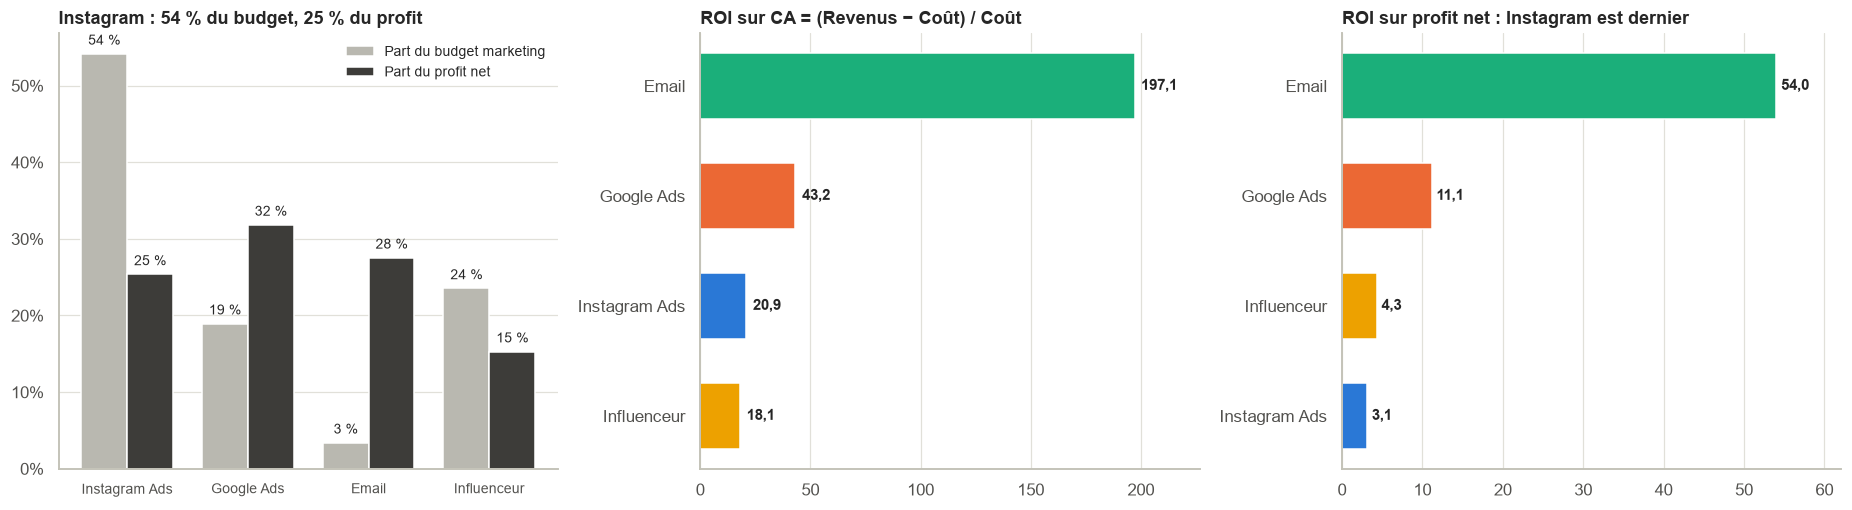

In [31]:
CANAUX = ["Instagram Ads", "Google Ads", "Email", "Influenceur"]
mkp = mk.loc[CANAUX]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
# (a) budget vs profit : qui consomme, qui rapporte
x = np.arange(4); w = .38
axes[0].bar(x - w/2, mkp["part_budget"], w, color=MES1, label="Part du budget marketing"); axes[0].bar(x + w/2, mkp["part_profit"], w, color=MES2, label="Part du profit net")
for i, (a, b) in enumerate(zip(mkp["part_budget"], mkp["part_profit"])):
    axes[0].text(i - w/2, a + .012, f"{pct(a,0)}", ha="center", fontsize=9); axes[0].text(i + w/2, b + .012, f"{pct(b,0)}", ha="center", fontsize=9)
axes[0].set_xticks(x); axes[0].set_xticklabels(CANAUX, fontsize=9); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); axes[0].legend(frameon=False, fontsize=9)
axes[0].set_title("Instagram : 54 % du budget, 25 % du profit"); axes[0].grid(axis="x", visible=False)
# (b) ROI (formule de l'énoncé)
order = mkp["roi"].sort_values().index
axes[1].barh(order, mkp.loc[order, "roi"], color=[C[c] for c in order], height=.6)
for i, c in enumerate(order): axes[1].text(mkp.loc[c, "roi"] + 3, i, nf(mkp.loc[c, "roi"], 1), va="center", fontsize=10, fontweight="bold")
axes[1].set_xlim(0, mkp["roi"].max()*1.15); axes[1].set_title("ROI sur CA = (Revenus − Coût) / Coût"); axes[1].grid(axis="y", visible=False)
# (c) ROI sur profit : la vue qui change le classement entre Instagram et Influenceur
order = mkp["roi_profit"].sort_values().index
axes[2].barh(order, mkp.loc[order, "roi_profit"], color=[C[c] for c in order], height=.6)
for i, c in enumerate(order): axes[2].text(mkp.loc[c, "roi_profit"] + .6, i, nf(mkp.loc[c, "roi_profit"], 1), va="center", fontsize=10, fontweight="bold")
axes[2].set_xlim(0, mkp["roi_profit"].max()*1.15); axes[2].set_title("ROI sur profit net : Instagram est dernier"); axes[2].grid(axis="y", visible=False)
plt.tight_layout(); sauver(fig, "fig_marketing"); plt.show()

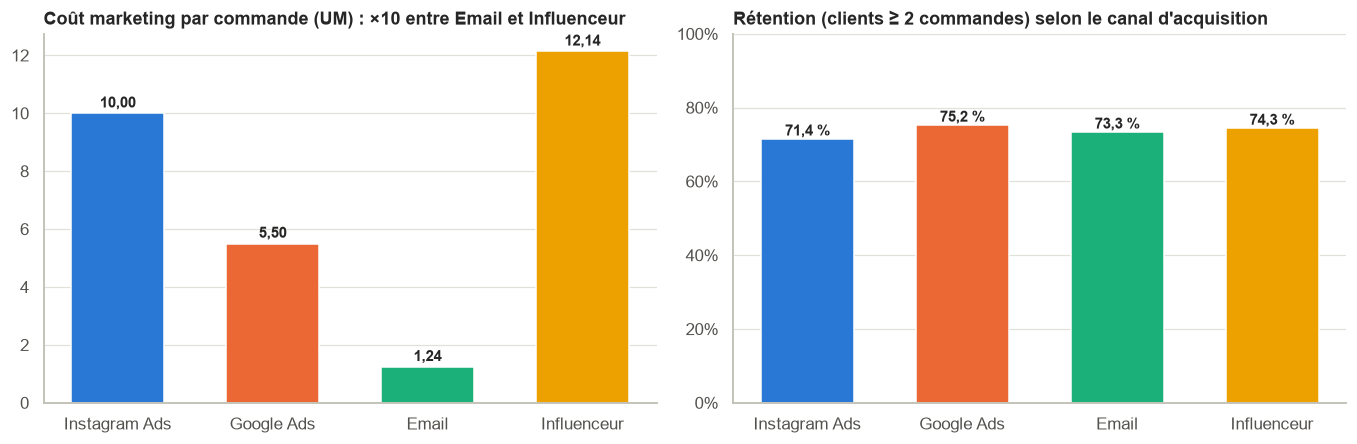

Le panier moyen et le mix produit sont quasi identiques d'un canal à l'autre : les canaux diffèrent par leur COÛT, pas par la qualité de la demande qu'ils amènent.
categorie       Électronique Maison Mode Beauté
canal_marketing                                
Instagram Ads            28%    21%  31%    20%
Google Ads               28%    19%  33%    20%
Email                    27%    21%  32%    19%
Influenceur              26%    20%  33%    21%


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
axes[0].bar(CANAUX, mkp["cout_par_commande"], color=[C[c] for c in CANAUX], width=.6)
for i, v in enumerate(mkp["cout_par_commande"]): axes[0].text(i, v + .2, nf(v, 2), ha="center", fontsize=10, fontweight="bold")
axes[0].set_title("Coût marketing par commande (UM) : ×10 entre Email et Influenceur"); axes[0].grid(axis="x", visible=False)
axes[1].bar(CANAUX, mkp["taux_retention"], color=[C[c] for c in CANAUX], width=.6)
for i, v in enumerate(mkp["taux_retention"]): axes[1].text(i, v + .01, pct(v), ha="center", fontsize=10, fontweight="bold")
axes[1].set_ylim(0, 1); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
axes[1].set_title("Rétention (clients ≥ 2 commandes) selon le canal d'acquisition"); axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print("Le panier moyen et le mix produit sont quasi identiques d'un canal à l'autre : les canaux diffèrent par leur COÛT, pas par la qualité de la demande qu'ils amènent.")
print(pd.crosstab(df["canal_marketing"], df["categorie"], normalize="index").loc[CANAUX, ORDRE_CAT].map("{:.0%}".format).to_string())

In [33]:
r3 = rap["r3"]
sens = pd.DataFrame({"Efficacité marginale de Google Ads (vs sa moyenne)": [.3, .4, .5, .7, 1.0]})
sens["Gain net de profit (UM, 6 mois)"] = [ap.simuler_reallocation(df, .25, e)["gain_net"] for e in sens.iloc[:, 0]]
display(Markdown(f'''
**Simulation de réallocation** : déplacer 25 % du budget Instagram + Influenceur ({nf(r3['montant'])} UM) vers Google Ads, à budget total constant.
Un canal « rapporte » en moyenne {nf(r3['rend_source'],1)} UM de profit avant marketing par UM dépensée (Instagram/Influenceur) contre {nf(r3['rend_google'],1)} pour Google Ads.
L'efficacité du **dernier** euro investi est toujours inférieure à la moyenne (rendements décroissants) ; la réallocation n'est gagnante que si Google conserve **au moins {pct(r3['seuil_efficacite'],0)}** de son efficacité moyenne :
'''))
display(sens.style.format({"Efficacité marginale de Google Ads (vs sa moyenne)": "{:.0%}", "Gain net de profit (UM, 6 mois)": "{:+,.0f}"}).hide(axis="index"))


**Simulation de réallocation** : déplacer 25 % du budget Instagram + Influenceur (13 499 UM) vers Google Ads, à budget total constant.
Un canal « rapporte » en moyenne 4,5 UM de profit avant marketing par UM dépensée (Instagram/Influenceur) contre 12,1 pour Google Ads.
L'efficacité du **dernier** euro investi est toujours inférieure à la moyenne (rendements décroissants) ; la réallocation n'est gagnante que si Google conserve **au moins 37 %** de son efficacité moyenne :


Efficacité marginale de Google Ads (vs sa moyenne),"Gain net de profit (UM, 6 mois)"
30%,"-11,146"
40%,"+5,248"
50%,"+21,642"
70%,"+54,430"
100%,"+103,612"


In [34]:
m_ = mk
display(Markdown(f'''
**Lecture business — marketing**
- **Instagram Ads** absorbe **{pct(m_.loc['Instagram Ads','part_budget'],0)} du budget** ({k(m_.loc['Instagram Ads','cout_marketing'])} UM) pour **{pct(m_.loc['Instagram Ads','part_profit'],0)} du profit** : ROI sur CA de {nf(m_.loc['Instagram Ads','roi'],1)} et ROI sur profit de seulement **{nf(m_.loc['Instagram Ads','roi_profit'],1)}** (le plus faible). Sa **rétention est aussi la plus basse** ({pct(m_.loc['Instagram Ads','taux_retention'])} contre {pct(m_.loc['Google Ads','taux_retention'])} pour Google Ads), l'écart restant modeste.
- **Influenceur** est le canal le plus cher par commande ({nf(m_.loc['Influenceur','cout_par_commande'],2)} UM) pour un ROI sur CA de {nf(m_.loc['Influenceur','roi'],1)} (le plus bas) : **à optimiser** (contrats à la performance, code promo traçable).
- **Google Ads** : ROI {nf(m_.loc['Google Ads','roi'],1)}, ROI sur profit {nf(m_.loc['Google Ads','roi_profit'],1)}, meilleure rétention ({pct(m_.loc['Google Ads','taux_retention'])}) : **le canal à renforcer**.
- **Email** : ROI exceptionnel ({nf(m_.loc['Email','roi'],0)}) pour {pct(m_.loc['Email','part_budget'],0)} du budget. Attention : l'email touche surtout une base **déjà acquise** ; il ne se « scale » pas comme un canal d'acquisition. Son vrai levier est la **rétention** (programme CRM).
- **Limite méthodologique** : l'attribution est « un canal par commande » (donnée fournie). Les ROI mesurent le rendement moyen, pas l'**incrémentalité** : c'est pourquoi la réallocation est proposée **par paliers testés**, pas d'un bloc.

> **Réponse à la question stratégique.** **Plus de budget : Google Ads** (et un programme **Email/CRM**). **Optimiser : Influenceur** (paiement à la performance). **Réduire : Instagram Ads**, de ≈ 25 %, avec ciblage recentré sur les profils qui rachètent. Test par paliers de 10 %, arrêt si le rendement marginal de Google tombe sous {pct(r3['seuil_efficacite'],0)} de sa moyenne.
'''))


**Lecture business — marketing**
- **Instagram Ads** absorbe **54 % du budget** (38 k UM) pour **25 % du profit** : ROI sur CA de 20,9 et ROI sur profit de seulement **3,1** (le plus faible). Sa **rétention est aussi la plus basse** (71,4 % contre 75,2 % pour Google Ads), l'écart restant modeste.
- **Influenceur** est le canal le plus cher par commande (12,14 UM) pour un ROI sur CA de 18,1 (le plus bas) : **à optimiser** (contrats à la performance, code promo traçable).
- **Google Ads** : ROI 43,2, ROI sur profit 11,1, meilleure rétention (75,2 %) : **le canal à renforcer**.
- **Email** : ROI exceptionnel (197) pour 3 % du budget. Attention : l'email touche surtout une base **déjà acquise** ; il ne se « scale » pas comme un canal d'acquisition. Son vrai levier est la **rétention** (programme CRM).
- **Limite méthodologique** : l'attribution est « un canal par commande » (donnée fournie). Les ROI mesurent le rendement moyen, pas l'**incrémentalité** : c'est pourquoi la réallocation est proposée **par paliers testés**, pas d'un bloc.

> **Réponse à la question stratégique.** **Plus de budget : Google Ads** (et un programme **Email/CRM**). **Optimiser : Influenceur** (paiement à la performance). **Réduire : Instagram Ads**, de ≈ 25 %, avec ciblage recentré sur les profils qui rachètent. Test par paliers de 10 %, arrêt si le rendement marginal de Google tombe sous 37 % de sa moyenne.


### 5.5 Analyse clients
**Question stratégique : comment améliorer la rétention ?**

In [35]:
nb = len(clients)
rec = clients["recurrent"].mean()
cl_sorted = clients.sort_values("ca_net", ascending=False).reset_index(drop=True)
cl_sorted["part_cum"] = cl_sorted["ca_net"].cumsum() / cl_sorted["ca_net"].sum()
n80 = int((cl_sorted["part_cum"] < 0.80).sum() + 1)
top20 = cl_sorted["ca_net"].head(int(nb * .2)).sum() / cl_sorted["ca_net"].sum()
top10 = cl_sorted["ca_net"].head(int(nb * .1)).sum() / cl_sorted["ca_net"].sum()
print(f"Clients acheteurs : {nb:,}".replace(",", " "))
print(f"Clients récurrents (≥ 2 commandes) : {pct(rec)}  |  Clients à 1 seul achat : {(clients['nb_commandes'] == 1).sum()} ({pct((clients['nb_commandes'] == 1).mean())})")
print(f"Fréquence : médiane {clients['nb_commandes'].median():.0f} commandes/client, moyenne {clients['nb_commandes'].mean():.1f}, max {clients['nb_commandes'].max()}")
print(f"Pareto : {n80} clients ({pct(n80/nb)}) génèrent 80 % du CA ; les 20 % meilleurs clients font {pct(top20,0)} du CA, les 10 % meilleurs {pct(top10,0)}.")
print(f"Délai médian entre 2 commandes d'un même client : {df[df['statut_commande']!='Annulée'].sort_values('date_commande').groupby('id_client')['date_commande'].apply(lambda s: s.diff().dt.days.median()).median():.0f} jours.")

Clients acheteurs : 1 734
Clients récurrents (≥ 2 commandes) : 73,2 %  |  Clients à 1 seul achat : 465 (26,8 %)
Fréquence : médiane 2 commandes/client, moyenne 5.3, max 28
Pareto : 536 clients (30,9 %) génèrent 80 % du CA ; les 20 % meilleurs clients font 65 % du CA, les 10 % meilleurs 41 %.


Délai médian entre 2 commandes d'un même client : 24 jours.


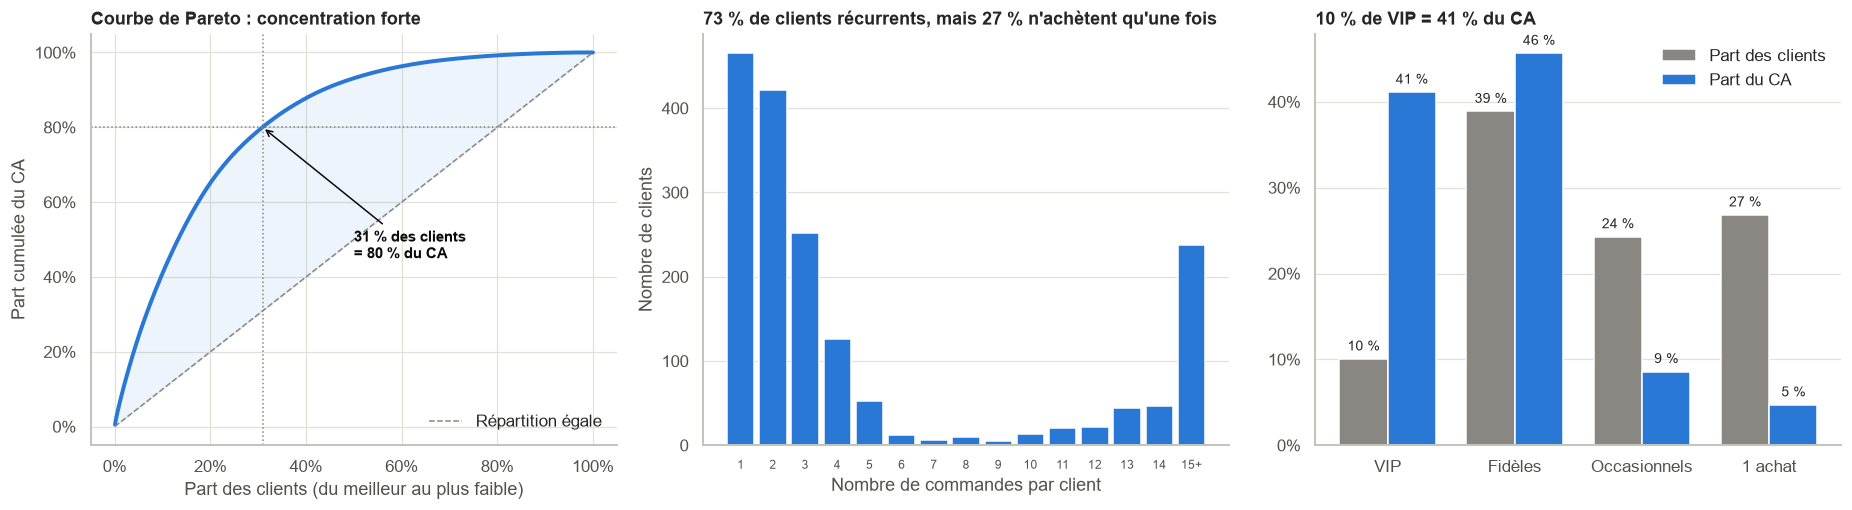

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
# (a) Pareto
xs = np.arange(1, nb + 1) / nb
axes[0].plot(xs, cl_sorted["part_cum"], color=BLEU, lw=2.6); axes[0].fill_between(xs, cl_sorted["part_cum"], xs, color=BLEU, alpha=.08)
axes[0].plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1, label="Répartition égale")
axes[0].axhline(.8, color=GRIS, lw=1, ls=":"); axes[0].axvline(n80 / nb, color=GRIS, lw=1, ls=":")
axes[0].annotate(f"{pct(n80/nb,0)} des clients\n= 80 % du CA", xy=(n80 / nb, .8), xytext=(.5, .45), arrowprops=dict(arrowstyle="->", color=C["texte"]), color=C["texte"], fontsize=10, fontweight="bold")
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
axes[0].set_xlabel("Part des clients (du meilleur au plus faible)"); axes[0].set_ylabel("Part cumulée du CA"); axes[0].set_title("Courbe de Pareto : concentration forte"); axes[0].legend(frameon=False, loc="lower right")
# (b) distribution du nombre de commandes
bins = clients["nb_commandes"].clip(upper=15)
axes[1].hist(bins, bins=np.arange(.5, 16.5, 1), color=BLEU, rwidth=.85)
axes[1].set_xticks(range(1, 16)); axes[1].set_xticklabels([str(i) for i in range(1, 15)] + ["15+"], fontsize=8)
axes[1].set_xlabel("Nombre de commandes par client"); axes[1].set_ylabel("Nombre de clients"); axes[1].set_title(f"{pct(rec,0)} de clients récurrents, mais {pct((clients['nb_commandes']==1).mean(),0)} n'achètent qu'une fois"); axes[1].grid(axis="x", visible=False)
# (c) segments : part des clients vs part du CA
SEG = ["VIP", "Fidèles", "Occasionnels", "Nouveaux (1 achat)"]
sg = clients.groupby("segment").agg(clients=("id_client", "count"), ca=("ca_net", "sum"), profit=("profit_net", "sum"), cmd=("nb_commandes", "mean")).loc[SEG]
sg["part_clients"] = sg["clients"] / sg["clients"].sum(); sg["part_ca"] = sg["ca"] / sg["ca"].sum(); sg["part_profit"] = sg["profit"] / sg["profit"].sum()
x = np.arange(4); w = .38
axes[2].bar(x - w/2, sg["part_clients"], w, color=GRIS, label="Part des clients"); axes[2].bar(x + w/2, sg["part_ca"], w, color=BLEU, label="Part du CA")
for i, (a, b) in enumerate(zip(sg["part_clients"], sg["part_ca"])):
    axes[2].text(i - w/2, a + .01, f"{pct(a,0)}", ha="center", fontsize=9); axes[2].text(i + w/2, b + .01, f"{pct(b,0)}", ha="center", fontsize=9)
axes[2].set_xticks(x); axes[2].set_xticklabels(["VIP", "Fidèles", "Occasionnels", "1 achat"]); axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); axes[2].legend(frameon=False)
axes[2].set_title("10 % de VIP = 41 % du CA"); axes[2].grid(axis="x", visible=False)
plt.tight_layout(); sauver(fig, "fig_clients"); plt.show()

In [37]:
print("Règles de segmentation (simples et actionnables) :")
print("  VIP = CA dans le top 10 % ET ≥ 3 commandes | Fidèles = ≥ 3 commandes | Occasionnels = 2 commandes | Nouveaux = 1 commande")
seg_tab = sg.join(clients.groupby("segment").agg(clv_moyenne=("profit_net", "mean"), ca_moyen=("ca_net", "mean"))).rename(columns={"cmd": "cmd_moyennes"})
display(seg_tab[["clients", "part_clients", "ca", "part_ca", "part_profit", "cmd_moyennes", "ca_moyen", "clv_moyenne"]]
        .style.format({"clients": "{:,.0f}", "part_clients": "{:.1%}", "ca": "{:,.0f}", "part_ca": "{:.1%}", "part_profit": "{:.1%}", "cmd_moyennes": "{:.1f}", "ca_moyen": "{:,.0f}", "clv_moyenne": "{:,.0f}"}))
print("\nTop 10 clients (par CA net) :")
top = cl_sorted.head(10)[["id_client", "nb_commandes", "ca_net", "profit_net", "ville_principale", "canal_acquisition", "segment"]].copy()
top.insert(0, "rang", range(1, 11)); top["part_du_CA_total"] = top["ca_net"] / clients["ca_net"].sum()
display(top.style.format({"ca_net": "{:,.0f}", "profit_net": "{:,.0f}", "part_du_CA_total": "{:.2%}"}).hide(axis="index"))
print(f"À eux dix : {pct(top['ca_net'].sum()/clients['ca_net'].sum())} du CA. Aucune dépendance excessive à un client individuel (le n°1 pèse {pct(top['part_du_CA_total'].iloc[0])}).")

Règles de segmentation (simples et actionnables) :
  VIP = CA dans le top 10 % ET ≥ 3 commandes | Fidèles = ≥ 3 commandes | Occasionnels = 2 commandes | Nouveaux = 1 commande


,clients,part_clients,ca,part_ca,part_profit,cmd_moyennes,ca_moyen,clv_moyenne
segment,,,,,,,,
VIP,174,10.0%,"897,472",41.1%,40.8%,17.4,"5,158","1,081"
Fidèles,674,38.9%,"996,358",45.6%,45.6%,7.3,"1,478",312
Occasionnels,421,24.3%,"187,073",8.6%,8.9%,2.0,444,97
Nouveaux (1 achat),465,26.8%,"102,302",4.7%,4.8%,1.0,220,47



Top 10 clients (par CA net) :


rang,id_client,nb_commandes,ca_net,profit_net,ville_principale,canal_acquisition,segment,part_du_CA_total
1,C0157,26,"11,373","2,396",Abidjan,Influenceur,VIP,0.52%
2,C0266,19,"10,606","1,980",Kinshasa,Instagram Ads,VIP,0.49%
3,C0051,17,"8,997","1,675",Kinshasa,Google Ads,VIP,0.41%
4,C0114,20,"8,875","1,893",Douala,Email,VIP,0.41%
5,C0379,25,"7,948","1,525",Abidjan,Influenceur,VIP,0.36%
6,C0184,19,"7,540","1,617",Dakar,Instagram Ads,VIP,0.35%
7,C0352,14,"7,485","1,663",Kinshasa,Google Ads,VIP,0.34%
8,C0364,19,"7,382","1,632",Kinshasa,Google Ads,VIP,0.34%
9,C0082,23,"7,372","1,619",Kinshasa,Google Ads,VIP,0.34%
10,C0273,22,"7,169","1,513",Kinshasa,Instagram Ads,VIP,0.33%


À eux dix : 3,9 % du CA. Aucune dépendance excessive à un client individuel (le n°1 pèse 0,5 %).


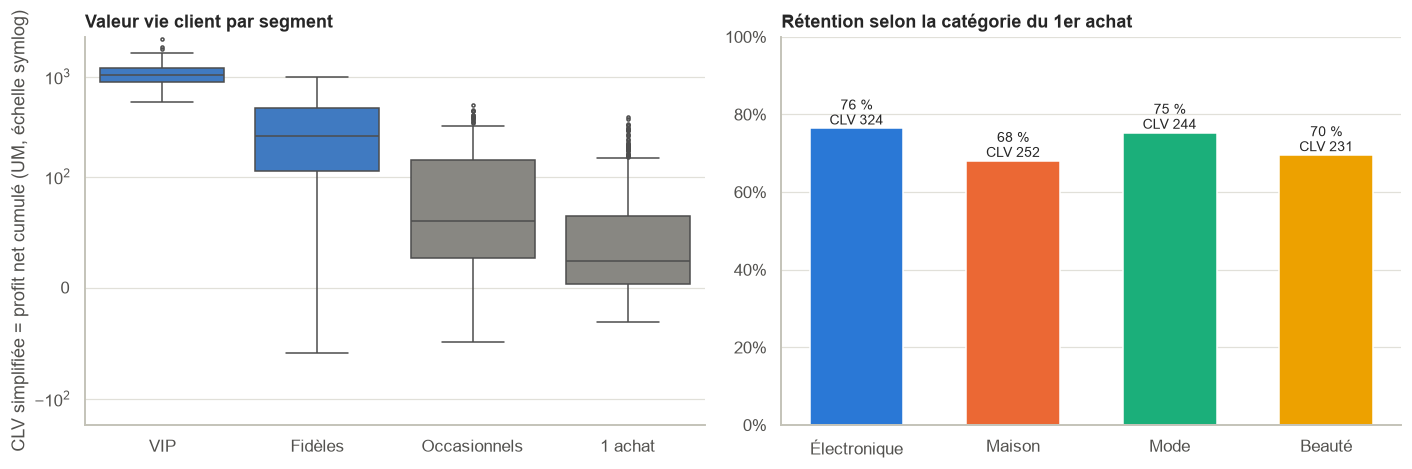

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
sns.boxplot(data=clients, x="segment", y="profit_net", order=SEG, palette=[BLEU, BLEU, GRIS, GRIS], ax=axes[0], fliersize=2, linewidth=1)
axes[0].set_yscale("symlog", linthresh=100); axes[0].set_xlabel(""); axes[0].set_ylabel("CLV simplifiée = profit net cumulé (UM, échelle symlog)")
axes[0].set_xticklabels(["VIP", "Fidèles", "Occasionnels", "1 achat"]); axes[0].set_title("Valeur vie client par segment")
cat1 = clients.groupby("categorie_1er_achat").agg(clients=("id_client", "count"), retention=("recurrent", "mean"), clv=("profit_net", "mean")).loc[ORDRE_CAT]
axes[1].bar(ORDRE_CAT, cat1["retention"], color=[C[c] for c in ORDRE_CAT], width=.6)
for i, (v, cl_) in enumerate(zip(cat1["retention"], cat1["clv"])): axes[1].text(i, v + .01, f"{pct(v,0)}\nCLV {nf(cl_)}", ha="center", fontsize=9)
axes[1].set_ylim(0, 1); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); axes[1].set_title("Rétention selon la catégorie du 1er achat"); axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

In [39]:
r5 = rap["r5"]
display(Markdown(f'''
**Lecture business — clients**
- **{nf(nb)} clients acheteurs, {pct(rec)} de récurrents** : la base est déjà fidèle (médiane de {clients['nb_commandes'].median():.0f} commandes, une commande tous les ~25 jours chez les clients actifs). Le gisement n'est donc pas « tout le monde », mais **trois poches précises**.
- **Concentration** : {pct(n80/nb,0)} des clients font 80 % du CA (on est plus proche d'un « 30/80 » que d'un « 20/80 ») ; les **{sg.loc['VIP','clients']:.0f} VIP (10 %)** font **{pct(sg.loc['VIP','part_ca'],0)} du CA** et **{pct(sg.loc['VIP','part_profit'],0)} du profit**. Perdre quelques VIP coûte cher ; le top 10 ne pèse toutefois que {pct(top['ca_net'].sum()/clients['ca_net'].sum())} du CA, donc pas de risque de dépendance à un seul compte.
- **Poche 1 – les « 1 achat »** : **{r5['nb_un_achat']} clients ({pct(r5['nb_un_achat']/nb,0)})** ne reviennent pas ; Instagram en compte {pct((clients.loc[clients['nb_commandes']==1,'canal_acquisition']=='Instagram Ads').mean(),0)} (pour {pct((clients['canal_acquisition']=='Instagram Ads').mean(),0)} de la base) : légèrement sur-représenté, sans être le seul responsable.
- **Poche 2 – les clients « à risque »** : **{r5['nb_risque']} clients** déjà récurrents sont inactifs depuis plus de 90 jours (**{k(r5['ca_risque'])} UM** de CA historique) alors que leur rythme normal est d'une commande par mois : ils décrochent.
- **Poche 3 – le 1er achat Électronique** donne la meilleure rétention ({pct(cat1.loc['Électronique','retention'],0)}) et la meilleure CLV ({nf(cat1.loc['Électronique','clv'])} UM) : l'Électronique est la porte d'entrée de valeur, ce qui renforce l'intérêt de **réduire ses retours** plutôt que de la déprioriser.
- Les écarts de rétention **entre canaux** sont modestes ({pct(mk['taux_retention'].min(),0)}–{pct(mk['taux_retention'].max(),0)}) : la fidélisation se gagne par l'**après-vente**, pas par le canal d'origine.

> **Réponse à la question stratégique.** (1) **Offre de 2ᵉ achat dans les 25 jours** (délai médian naturel) pour les clients à 1 achat ; (2) **campagne de réactivation à J+60/J+90** pour les 130 clients à risque ; (3) **programme VIP** (livraison offerte, accès anticipé Maison/Électronique) pour protéger 41 % du CA ; (4) **ventes croisées Maison** après un 1er achat Électronique (Maison = meilleur taux de profit).
'''))


**Lecture business — clients**
- **1 734 clients acheteurs, 73,2 % de récurrents** : la base est déjà fidèle (médiane de 2 commandes, une commande tous les ~25 jours chez les clients actifs). Le gisement n'est donc pas « tout le monde », mais **trois poches précises**.
- **Concentration** : 31 % des clients font 80 % du CA (on est plus proche d'un « 30/80 » que d'un « 20/80 ») ; les **174 VIP (10 %)** font **41 % du CA** et **41 % du profit**. Perdre quelques VIP coûte cher ; le top 10 ne pèse toutefois que 3,9 % du CA, donc pas de risque de dépendance à un seul compte.
- **Poche 1 – les « 1 achat »** : **465 clients (27 %)** ne reviennent pas ; Instagram en compte 42 % (pour 39 % de la base) : légèrement sur-représenté, sans être le seul responsable.
- **Poche 2 – les clients « à risque »** : **130 clients** déjà récurrents sont inactifs depuis plus de 90 jours (**63 k UM** de CA historique) alors que leur rythme normal est d'une commande par mois : ils décrochent.
- **Poche 3 – le 1er achat Électronique** donne la meilleure rétention (76 %) et la meilleure CLV (324 UM) : l'Électronique est la porte d'entrée de valeur, ce qui renforce l'intérêt de **réduire ses retours** plutôt que de la déprioriser.
- Les écarts de rétention **entre canaux** sont modestes (71 %–75 %) : la fidélisation se gagne par l'**après-vente**, pas par le canal d'origine.

> **Réponse à la question stratégique.** (1) **Offre de 2ᵉ achat dans les 25 jours** (délai médian naturel) pour les clients à 1 achat ; (2) **campagne de réactivation à J+60/J+90** pour les 130 clients à risque ; (3) **programme VIP** (livraison offerte, accès anticipé Maison/Électronique) pour protéger 41 % du CA ; (4) **ventes croisées Maison** après un 1er achat Électronique (Maison = meilleur taux de profit).


## 6. Test de robustesse
Les conclusions reposent sur deux choix qui pourraient être contestés : (a) les **taux de coût d'achat** (hypothèse, absents des données) ; (b) la **suppression des quantités nulles**. On vérifie que les classements qui fondent les recommandations ne changent pas.

In [40]:
def classements(d):
    return {
        "Catégorie n°1 en profit": d.groupby("categorie")["profit_net"].sum().idxmax(),
        "Catégorie la + rentable (profit/CA)": (d.groupby("categorie")["profit_net"].sum() / d.groupby("categorie")["ca_net"].sum()).idxmax(),
        "Ville n°1 en CA": d.groupby("ville")["ca_net"].sum().idxmax(),
        "Ville au plus fort taux d'annulation": d.groupby("ville")["indicateur_annulation"].mean().idxmax(),
        "Canal au meilleur ROI sur profit": ap.agg_dimension(d, "canal_marketing")["roi_profit"].idxmax(),
        "Canal au plus faible ROI sur profit": ap.agg_dimension(d, "canal_marketing")["roi_profit"].idxmin(),
        "Catégorie au plus fort taux de retour": d.groupby("categorie")["indicateur_retour"].mean().idxmax(),
    }
scen = {
    "Base": df,
    "Coût d'achat −10 pts": ap.ajouter_features(df_clean, {k_: v - .10 for k_, v in ap.COGS_RATE_DEFAUT.items()}),
    "Coût d'achat +10 pts": ap.ajouter_features(df_clean, {k_: v + .10 for k_, v in ap.COGS_RATE_DEFAUT.items()}),
    "Quantités nulles imputées (au lieu de supprimées)": ap.charger_clean(quantite_zero="imputer")[0],
}
rob = pd.DataFrame({n: classements(d) for n, d in scen.items()})
display(rob)
stable = (rob.nunique(axis=1) == 1)
print(f"\n{stable.sum()} classements sur {len(stable)} identiques dans les 4 scénarios.")
for n, d in scen.items():
    print(f"  {n:<52} CA net {nf(d['ca_net'].sum()):>10} | profit net {nf(d['profit_net'].sum()):>9} ({pct(d['profit_net'].sum()/d['ca_net'].sum())})")

,Base,Coût d'achat −10 pts,Coût d'achat +10 pts,Quantités nulles imputées (au lieu de supprimées)
Catégorie n°1 en profit,Électronique,Électronique,Électronique,Électronique
Catégorie la + rentable (profit/CA),Maison,Maison,Maison,Maison
Ville n°1 en CA,Kinshasa,Kinshasa,Kinshasa,Kinshasa
Ville au plus fort taux d'annulation,Douala,Douala,Douala,Douala
Canal au meilleur ROI sur profit,Email,Email,Email,Email
Canal au plus faible ROI sur profit,Instagram Ads,Instagram Ads,Instagram Ads,Instagram Ads
Catégorie au plus fort taux de retour,Électronique,Électronique,Électronique,Électronique



7 classements sur 7 identiques dans les 4 scénarios.
  Base                                                 CA net  2 183 205 | profit net   460 831 (21,1 %)
  Coût d'achat −10 pts                                 CA net  2 183 205 | profit net   704 773 (32,3 %)
  Coût d'achat +10 pts                                 CA net  2 183 205 | profit net   216 890 (9,9 %)
  Quantités nulles imputées (au lieu de supprimées)    CA net  2 330 442 | profit net   492 724 (21,1 %)


**Verdict :** les conclusions structurantes (Électronique = n°1 en profit mais n°1 en retours ; Maison la plus rentable ; Douala = anomalie d'annulation ; Google/Email > Instagram en rendement) **ne dépendent ni des taux de coût d'achat ni du traitement des quantités nulles**. Seul le *niveau* absolu du profit varie, ce qu'il faut garder en tête quand on cite un montant (ordre de grandeur, pas comptabilité).

## 7. Recommandations stratégiques

In [41]:
r = rap
reco = pd.DataFrame([
    ["1", "Corriger les annulations à Douala",
     f"{pct(r['r1']['taux_douala'])} d'annulations vs {pct(r['r1']['taux_ref'])} ailleurs ; {k(r['r1']['ca_annule'])} UM de CA perdu",
     "Audit opérationnel Douala sous 30 jours (stock, délai de livraison, confirmation de commande, paiement) ; plan correctif puis tableau de bord hebdo",
     "Taux d'annulation Douala < 3 % à 90 jours", r["r1"]["impact"]],
    ["2", "Réduire les retours Électronique",
     f"{pct(r['r2']['taux'])} de retours (2 à 5× les autres) ; {k(r['r2']['ca_rembourse'])} UM remboursées",
     "Revue qualité/fournisseurs des 15 produits les plus retournés, fiches produit (compatibilité, photos, garantie), contrôle avant expédition, motif de retour obligatoire",
     f"Taux de retour Électronique ≤ {pct(r['r2']['cible'],0)} à 6 mois", r["r2"]["impact"]],
    ["3", "Réallouer le marketing d'Instagram vers Google Ads et l'Email",
     f"Instagram : 54 % du budget, 25 % du profit, ROI profit {nf(mk.loc['Instagram Ads','roi_profit'],1)} vs Google {nf(mk.loc['Google Ads','roi_profit'],1)}",
     "Transférer 25 % du budget Instagram+Influenceur vers Google Ads par paliers de 10 % testés ; Influenceur payé à la performance ; lancer un programme Email/CRM",
     f"ROI profit global ↑ ; arrêt si rendement marginal Google < {pct(r['r3']['seuil_efficacite'],0)} de sa moyenne", r["r3"]["impact"]],
    ["4", "Prioriser Maison, redresser Mode",
     f"Maison : profit/CA {pct(cat.loc['Maison','taux_profit'])}, T4 {pcs(r['r4']['maison_t4_t3'])} ; Mode : T4 {pcs(r['r4']['mode_t4_t3'])}",
     "Sécuriser stock et campagnes Maison pour le pic nov-déc ; ventes croisées Maison aux acheteurs Électronique ; diagnostic offre/prix Mode",
     "Part Maison dans le profit ↑ ; Mode revient au CA du T3", r["r4"]["impact"]],
    ["5", "Programme de rétention ciblé",
     f"{r['r5']['nb_un_achat']} clients à 1 achat, {r['r5']['nb_risque']} clients à risque ({k(r['r5']['ca_risque'])} UM), VIP = 41 % du CA",
     "Offre 2ᵉ achat sous 25 jours ; réactivation J+60/J+90 ; programme VIP ; ventes croisées",
     "Taux de récurrence 73 % → 78 % ; ≥ 30 % des clients à risque réactivés", r["r5"]["impact"]],
], columns=["#", "Recommandation", "Constat chiffré", "Action", "KPI cible", "Impact profit estimé (UM, 6 mois)"])
display(reco.style.format({"Impact profit estimé (UM, 6 mois)": "{:+,.0f}"}).hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
print(f"\nImpact cumulé estimé : {nf(r['total_impact'])} UM de profit sur 6 mois = +{pct(r['total_impact']/r['profit_base'])} par rapport au profit net actuel ({nf(r['profit_base'])} UM), soit environ {nf(2*r['total_impact'])} UM en année pleine.")

#,Recommandation,Constat chiffré,Action,KPI cible,"Impact profit estimé (UM, 6 mois)"
1,Corriger les annulations à Douala,"12,9 % d'annulations vs 0,1 % ailleurs ; 47 k UM de CA perdu","Audit opérationnel Douala sous 30 jours (stock, délai de livraison, confirmation de commande, paiement) ; plan correctif puis tableau de bord hebdo",Taux d'annulation Douala < 3 % à 90 jours,"+7,268"
2,Réduire les retours Électronique,"15,6 % de retours (2 à 5× les autres) ; 282 k UM remboursées","Revue qualité/fournisseurs des 15 produits les plus retournés, fiches produit (compatibilité, photos, garantie), contrôle avant expédition, motif de retour obligatoire",Taux de retour Électronique ≤ 10 % à 6 mois,"+21,685"
3,Réallouer le marketing d'Instagram vers Google Ads et l'Email,"Instagram : 54 % du budget, 25 % du profit, ROI profit 3,1 vs Google 11,1",Transférer 25 % du budget Instagram+Influenceur vers Google Ads par paliers de 10 % testés ; Influenceur payé à la performance ; lancer un programme Email/CRM,ROI profit global ↑ ; arrêt si rendement marginal Google < 37 % de sa moyenne,"+21,642"
4,"Prioriser Maison, redresser Mode","Maison : profit/CA 32,0 %, T4 +68 % ; Mode : T4 -17 %",Sécuriser stock et campagnes Maison pour le pic nov-déc ; ventes croisées Maison aux acheteurs Électronique ; diagnostic offre/prix Mode,Part Maison dans le profit ↑ ; Mode revient au CA du T3,"+3,770"
5,Programme de rétention ciblé,"465 clients à 1 achat, 130 clients à risque (63 k UM), VIP = 41 % du CA",Offre 2ᵉ achat sous 25 jours ; réactivation J+60/J+90 ; programme VIP ; ventes croisées,Taux de récurrence 73 % → 78 % ; ≥ 30 % des clients à risque réactivés,"+5,230"



Impact cumulé estimé : 59 594 UM de profit sur 6 mois = +12,9 % par rapport au profit net actuel (460 831 UM), soit environ 119 189 UM en année pleine.


**Hypothèses de chiffrage (volontairement prudentes)** — *ce sont des ordres de grandeur, pas des engagements :*
1. **Douala** : on récupère 70 % des annulations en excès (par rapport au taux des autres villes) ; chaque commande récupérée rapporte la marge brute moyenne moins la livraison (le marketing est déjà dépensé).
2. **Retours Électronique** : de 15,6 % à 10 % ; chaque retour évité devient une vente conservée (marge brute moyenne + une livraison retour économisée).
3. **Marketing** : 25 % d'Instagram+Influenceur → Google Ads, efficacité marginale de Google = 50 % de sa moyenne (l'analyse de sensibilité en 5.4 montre le seuil de rentabilité à ≈ 37 %).
4. **Mode** : retour du CA du T4 au niveau du T3 (au taux de profit de Mode). L'effet Maison est une protection du pic de fin d'année, non comptée dans le total.
5. **Rétention** : 30 % des clients à risque réactivés (3 mois d'activité au rythme historique) + 15 % des clients à 1 achat font une 2ᵉ commande ; profit au taux moyen des clients.

## 8. Conclusion

In [42]:
display(Markdown(f'''
### Où en est AfriMarket ?
AfriMarket est **rentable et stable** ({nf(kp['ca_total'])} UM de CA net, {nf(kp['profit_net'])} UM de profit net, {pct(kp['profit_net']/kp['ca_total'])} du CA) avec une base de clients fidèle ({pct(rec,0)} de récurrents). Les quatre alertes de la direction s'expliquent par **des causes précises et corrigeables** :

| Alerte de la direction | Cause identifiée | Levier |
|---|---|---|
| Taux de retour préoccupant | **Électronique** : {pct(cat.loc['Électronique','taux_retour'])} de retours, structurel sur les 50 produits | Qualité/fiches produit (reco 2) |
| Écarts entre villes | **Douala** : {pct(r['r1']['taux_douala'])} d'annulations (≈ 0 % ailleurs) ; **Cotonou** accélère ; **Dakar/Abidjan** stagnent | Opérations Douala (reco 1), investissement ciblé |
| Dépenses marketing élevées | **Instagram** : 54 % du budget pour 25 % du profit | Réallocation vers Google/Email (reco 3) |
| Variations du CA | Bascule de mix de fin d'année : **Maison ×2, Mode −17 %** | Anticipation stock/offre (reco 4) |

### Plan d'action
| Horizon | Actions | Responsable suggéré |
|---|---|---|
| **30 jours** | Audit opérationnel Douala ; revue qualité des 15 produits Électronique les plus retournés ; mise en place du suivi hebdo (annulation, retour, ROI par canal) | Opérations / Qualité / Data |
| **60 jours** | Premier palier de réallocation marketing (−10 % Instagram → Google) et mesure ; lancement des relances « 2ᵉ achat » et réactivation | Marketing / CRM |
| **90 jours** | Programme VIP ; ventes croisées Maison ; plan stock Maison pour le prochain pic ; décision sur le palier suivant de réallocation | Direction commerciale |

**Gain attendu : environ +{nf(r['total_impact']/1e3)} k UM de profit sur 6 mois (+{pct(r['total_impact']/r['profit_base'],0)}), soit ≈ {nf(2*r['total_impact']/1e3)} k UM par an**, sans augmenter le budget total.

### Limites à garder en tête
- Le **coût d'achat est une hypothèse** (absent des données) ; les montants de profit sont des ordres de grandeur, mais les **classements et recommandations sont robustes** (§6).
- 6 mois d'historique : pas de saisonnalité annuelle ; la hausse Maison de nov-déc peut être un pic de fin d'année plutôt qu'une tendance.
- Attribution marketing « un canal par commande » : ROI moyens, non incrémentaux ; d'où le test par paliers.
- 600 lignes à quantité nulle (6 %) ont été écartées ; ce choix ne change aucun classement (§6).

**Prochaine étape recommandée :** collecter le **coût d'achat réel** et le **motif des retours/annulations** : ces deux champs transformeront ces hypothèses en mesures.
'''))


### Où en est AfriMarket ?
AfriMarket est **rentable et stable** (2 183 205 UM de CA net, 460 831 UM de profit net, 21,1 % du CA) avec une base de clients fidèle (73 % de récurrents). Les quatre alertes de la direction s'expliquent par **des causes précises et corrigeables** :

| Alerte de la direction | Cause identifiée | Levier |
|---|---|---|
| Taux de retour préoccupant | **Électronique** : 15,6 % de retours, structurel sur les 50 produits | Qualité/fiches produit (reco 2) |
| Écarts entre villes | **Douala** : 12,9 % d'annulations (≈ 0 % ailleurs) ; **Cotonou** accélère ; **Dakar/Abidjan** stagnent | Opérations Douala (reco 1), investissement ciblé |
| Dépenses marketing élevées | **Instagram** : 54 % du budget pour 25 % du profit | Réallocation vers Google/Email (reco 3) |
| Variations du CA | Bascule de mix de fin d'année : **Maison ×2, Mode −17 %** | Anticipation stock/offre (reco 4) |

### Plan d'action
| Horizon | Actions | Responsable suggéré |
|---|---|---|
| **30 jours** | Audit opérationnel Douala ; revue qualité des 15 produits Électronique les plus retournés ; mise en place du suivi hebdo (annulation, retour, ROI par canal) | Opérations / Qualité / Data |
| **60 jours** | Premier palier de réallocation marketing (−10 % Instagram → Google) et mesure ; lancement des relances « 2ᵉ achat » et réactivation | Marketing / CRM |
| **90 jours** | Programme VIP ; ventes croisées Maison ; plan stock Maison pour le prochain pic ; décision sur le palier suivant de réallocation | Direction commerciale |

**Gain attendu : environ +60 k UM de profit sur 6 mois (+13 %), soit ≈ 119 k UM par an**, sans augmenter le budget total.

### Limites à garder en tête
- Le **coût d'achat est une hypothèse** (absent des données) ; les montants de profit sont des ordres de grandeur, mais les **classements et recommandations sont robustes** (§6).
- 6 mois d'historique : pas de saisonnalité annuelle ; la hausse Maison de nov-déc peut être un pic de fin d'année plutôt qu'une tendance.
- Attribution marketing « un canal par commande » : ROI moyens, non incrémentaux ; d'où le test par paliers.
- 600 lignes à quantité nulle (6 %) ont été écartées ; ce choix ne change aucun classement (§6).

**Prochaine étape recommandée :** collecter le **coût d'achat réel** et le **motif des retours/annulations** : ces deux champs transformeront ces hypothèses en mesures.
